# Predictive Maintenance Framework for Marine Hydraulic Systems and Critical Shipboard Machinery

**Capstone Project-Marine Engineering**


## Abstract (NOT FINAL YET)

Background of the study:nothing here yet

Methods: This study builds a complete CBM classification pipeline on the **ZeMA hydraulic test-rig dataset** (Helwig, Pignanelli & Schütze, 2015; UCI ML Repository ID 447) - **2,205 measured 60-second duty cycles across 17 physical and virtual sensor channels**, including pressure, volume flow, motor power, four circuit temperatures and a **vibration channel**, with cycle-wise ground-truth annotations for four independently degraded components. Unlike most published predictive-maintenance benchmarks, **this is genuine physical measurement from an instrumented rig, not simulator output and not synthetically generated data.** from here: https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems


Each 60-second cycle is compressed into **physically interpretable statistical descriptors per sensor**

Four classifiers are compared under stratified 5-fold cross-validation: **Decision Tree** (as an auditable, surveyor-inspectable baseline), **Random Forest**, **Histogram Gradient Boosting**, and **XGBoost** where available.

The trained model is deployed as an **interactive Chief Engineer diagnostic console** that accepts live sensor readings and returns a three-state verdict with calibrated class probabilities, the physical channels driving the decision, and an ISO-referenced recommended action.

---

## Standards Cross-Check

### A. Standards framework (sinearch and pina AI ko lang relative to the data, you can review and add or omit)

| Instrument | Relevance |
|---|---|
| **ISO 10816-1/-3/-6** and its successor **ISO 20816-1:2016** - *Mechanical vibration - Measurement and evaluation of machine vibration* | Defines evaluation **zones A/B/C/D** (A = newly commissioned, B = acceptable for unrestricted long-term operation, C = unsatisfactory for continuous operation, D = damage likely) in terms of **RMS vibration velocity, mm/s**. Part 6 addresses reciprocating machines above 100 kW — the shipboard diesel generator case. Our `VS1_rms` feature is computed in exactly these units and semantics. |
| **ISO 20283-4** - *Mechanical vibration - Measurement of vibration on ships* | Shipboard-specific measurement and evaluation of machinery vibration. |
| **ISO 13374-1/-2** — *Condition monitoring and diagnostics of machines — Data processing, communication and presentation* | Defines the six-block reference architecture (DA → DM → SD → HA → PA → AG). Sections 3–9 of this notebook map one-to-one onto those blocks. |
| **ISO 17359:2018** — *Condition monitoring and diagnostics of machines — General guidelines* | Requires criticality analysis, parameter selection and alarm-criteria justification before deployment — the rationale for Sections 8 and 9. |
| **ISO 13381-1** — *Prognostics* | Framework for extending state detection to remaining-useful-life estimation; identified as the natural extension in Section 10.5. |
| **ISO 8528-1** — *Reciprocating internal combustion engine driven alternating current generating sets* | Performance classes and operating-limit definitions for the shipboard diesel generator this framework targets. |
| **IEEE Std 493 (Gold Book)** — *Design of Reliable Industrial and Commercial Power Systems* | Reliability-data methodology and failure-rate framework underpinning quantitative RCM decisions for the ship's electrical plant. |
| **SOLAS Ch. II-1 Reg. 29; IACS UR M** | Steering-gear and machinery redundancy requirements — the regulatory reason auxiliary hydraulic health is safety-critical, not merely economic. |
| **MARPOL Annex VI Reg. 13** | NOₓ Tier limits: a fouled charge-air cooler raises scavenge-air temperature and NOₓ output, so cooler condition is an *emissions*-compliance parameter as well as a reliability one. |




### B. Peer-reviewed literature

- **Helwig, N., Pignanelli, E. & Schütze, A. (2015).** *Condition monitoring of a complex hydraulic system using multivariate statistics.* IEEE International Instrumentation and Measurement Technology Conference (I2MTC), 210–215. DOI 10.1109/I2MTC.2015.7151267. — **The source publication for the dataset used here.** Establishes the test rig, the superimposed fault types and the severity grading. ito link: https://www.researchgate.net/publication/283428892_Condition_monitoring_of_a_complex_hydraulic_system_using_multivariate_statistics

Hanap kayo ng literature about : Machinery diagnostics and prognostics implementing condition-based maintenance. for establishing the data-acquisition → data-processing → decision-making structure adopted here.

Another literature for: Prognostics and health management design for machinery systems.

Another literature for: Machine learning approaches for improving condition-based maintenance

Another literature for: Explainable artificial intelligence for predictive maintenance applications.

Ito lang need para mabuo ung background.

### C. Identified research gap (kayo na maglalagay) based on the literatures above.

## 1. Environment Setup, Dependency Verification and Seed Initialisation

Intallation part lang ito, like mga softwares na need para mai-runung data.from Python workspace, ung programming language ay "Pythom", and definition of standard alert colors para sa dashboard.



In [ ]:
# =====================================================================
# CELL 1 — Environment, dependencies, reproducibility
# =====================================================================
import importlib, subprocess, sys, os, io, time, warnings, urllib.request, urllib.error

REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib", "seaborn": "seaborn", "scipy": "scipy",
}

missing = []
for module_name, pip_name in REQUIRED.items():
    try:
        importlib.import_module(module_name)
    except ImportError:
        missing.append(pip_name)

if missing:
    print(f"Installing missing core packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required core packages are present.")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# --- optional accelerated booster, with a graceful in-library fallback ---
HAS_XGBOOST = False
try:
    import xgboost                                    # noqa: F401
    HAS_XGBOOST = True
except ImportError:
    # Attempt a quiet install. Output is captured so that a failure on a locked
    # -down runtime produces one tidy line rather than a wall of pip diagnostics.
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"],
                       capture_output=True, text=True, timeout=300)
        import xgboost                                # noqa: F401
        HAS_XGBOOST = True
    except Exception:
        HAS_XGBOOST = False

print("XGBoost available:", HAS_XGBOOST,
      "" if HAS_XGBOOST else "-> falling back to sklearn HistGradientBoostingClassifier "
                              "(same algorithm family; no loss of rigour).")

# ---------------------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5.5), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "font.size": 10, "legend.frameon": True,
})
GREEN, AMBER, RED, NAVY, SLATE = "#0f7b6c", "#c98a00", "#b5241c", "#1b3a5c", "#5c6b73"
STATE_COLOURS = [GREEN, AMBER, RED]
STATE_NAMES = ["OPERATIONAL NORMAL", "WARNING", "CRITICAL"]

print(f"\nPython {sys.version.split()[0]} | numpy {np.__version__} | "
      f"pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"RANDOM_STATE = {RANDOM_STATE}")

All required core packages are present.
XGBoost available: True 

Python 3.13.15 | numpy 2.1.3 | pandas 2.2.3 | seaborn 0.13.2
RANDOM_STATE = 42


## 2. Data Acquisition Pipeline

Ito yung data source, all information are from the website na, pina-arrange ko na din sa script para clean ung data source which actually is already possesses by the data.

**Dataset:** *Condition Monitoring of Hydraulic Systems* — UCI ML Repository ID 447 (DOI 10.24432/C5CW21), donated April 2018 by **ZeMA gGmbH, Saarbrücken**, and the Lab for Measurement Technology, Saarland University.

**Origin:** A physical hydraulic test rig comprising a **primary working circuit** and a **secondary cooling-and-filtration circuit** joined by a common oil tank. The rig repeats constant 60-second load cycles while four components — cooler, valve, pump and accumulator — are independently and quantitatively degraded. Gathering physical evidence stage. It collects direct measurements like temperature and pressure from 2,205 60-second engine runs
(galing sa data source)

| Rig channel | Shipboard analogue | Why an engineer watches it |
|---|---|---|
| `TS1`–`TS4` (°C) | Jacket-water, lube-oil, charge-air and sea-water circuit temperatures | Rising outlet temperature is the primary signature of **heat-exchanger fouling** |
| `VS1` (mm/s) | Machinery vibration velocity, **the ISO 20816 severity quantity** | Bearing wear, misalignment, cavitation, imbalance |
| `PS1` (bar) | Lubricating-oil / working-circuit pressure | Pump wear, internal leakage, filter blockage |
| `FS1`, `FS2` (l/min) | Cooling-water and lube-oil flow rates | Restriction, air ingress, pump degradation |
| `EPS1` (W) | Driving-motor electrical power | Load-side proxy for hydraulic demand |

### 2.3 Sensor inventory and file structure

Each file is a tab-delimited matrix: **rows = 2,205 duty cycles**, **columns = samples within one 60-second cycle**. Sampling rates differ by channel, so column counts differ.

| Sensor | Quantity | Unit | Rate | Cols/cycle | Approx. size |
|---|---|---|---|---|---|
| `PS1`–`PS6` | Pressure | bar | 100 Hz | 6,000 | ~70–91 MB each |
| `EPS1` | Motor power | W | 100 Hz | 6,000 | ~87 MB |
| `FS1`, `FS2` | Volume flow | l/min | 10 Hz | 600 | ~8 MB each |
| `TS1`–`TS4` | Temperature | °C | 1 Hz | 60 | ~0.9 MB each |
| `VS1` | **Vibration** | mm/s | 1 Hz | 60 | ~0.8 MB |
| `CE`, `CP`, `SE` | *Virtual* efficiency channels | %, kW, % | 1 Hz | 60 | ~0.9 MB each |

Ground-truth labels (`profile.txt`, 5 columns)

| Col | Component | Values |
|---|---|---|
| 1 | **Cooler condition** | 100 = full efficiency · 20 = reduced · 3 = close to total failure |
| 2 | Valve condition | 100 = optimal · 90 = small lag · 80 = severe lag · 73 = near failure |
| 3 | Internal pump leakage | 0 = none · 1 = weak · 2 = severe |
| 4 | Hydraulic accumulator | 130 · 115 · 100 · 90 bar (falling = worse) |
| 5 | Stable flag | 0 = steady conditions · 1 = steady state possibly not reached |

In [ ]:
# =====================================================================
# CELL 2 — Robust multi-channel data acquisition
# =====================================================================

MIRRORS = [
    "https://raw.githubusercontent.com/Machine-Learning-FGA/Hydraulic-systems/master/data",
]

# Physical transducers ONLY. CE / CP / SE are virtual channels derived from the
# thermodynamic state we are trying to predict and are excluded to prevent
# target leakage -- see Section 8 for the quantified demonstration.
PHYSICAL_SENSORS = {
    "TS1": ("Temperature - circuit 1", "degC", 1),
    "TS2": ("Temperature - circuit 2", "degC", 1),
    "TS3": ("Temperature - circuit 3", "degC", 1),
    "TS4": ("Temperature - cooler outlet", "degC", 1),
    "VS1": ("Vibration velocity", "mm/s", 1),
    "FS1": ("Volume flow 1", "l/min", 10),
    "FS2": ("Volume flow 2", "l/min", 10),
}
LEAKY_VIRTUAL_SENSORS = ["CE", "CP", "SE"]

INCLUDE_PS1 = True           # ~91 MB, lubricating-oil pressure analogue
INCLUDE_ALL_PRESSURE = False # opt-in: adds PS2-PS6 + EPS1 (~400 MB)

EXPECTED_CYCLES = 2205


def fetch_channel(name, timeout=600, retries=2, required=True):
    """
    Download and parse one sensor matrix with layered fault tolerance.

    Returns a float32 array of shape (cycles, samples_per_cycle), or None if the
    channel is optional and could not be retrieved.
    """
    failures = []
    for base in MIRRORS:
        url = f"{base}/{name}.txt"
        for attempt in range(1, retries + 1):
            try:
                t0 = time.time()
                request = urllib.request.Request(
                    url, headers={"User-Agent": "Mozilla/5.0 (capstone-research)"})
                with urllib.request.urlopen(request, timeout=timeout) as response:
                    payload = response.read()

                matrix = pd.read_csv(io.BytesIO(payload), sep="\t", header=None,
                                     dtype=np.float32).values

                if matrix.ndim != 2 or matrix.shape[0] < 100:
                    raise ValueError(f"unexpected shape {matrix.shape}")
                if not np.isfinite(matrix).all():
                    raise ValueError("non-finite values present after parsing")

                print(f"  {name:<5s} {matrix.shape[0]:,} cycles x "
                      f"{matrix.shape[1]:>5,} samples  "
                      f"({len(payload)/1e6:6.1f} MB, {time.time()-t0:5.1f}s)")
                return matrix

            except Exception as exc:
                failures.append(f"{url} attempt {attempt}: {type(exc).__name__}: {exc}")
                time.sleep(1.5 * attempt)

    message = f"Could not retrieve channel '{name}'.\n  - " + "\n  - ".join(failures)
    if required:
        raise RuntimeError(message)
    print(f"  WARNING  optional channel {name} unavailable; continuing without it.")
    return None


print("Downloading physical sensor channels")
print("-" * 66)
raw_channels, channel_rates = {}, {}
for sensor, (description, unit, rate) in PHYSICAL_SENSORS.items():
    raw_channels[sensor] = fetch_channel(sensor, required=True)
    channel_rates[sensor] = rate

if INCLUDE_PS1:
    ps1 = fetch_channel("PS1", required=False)
    if ps1 is not None:
        raw_channels["PS1"] = ps1
        channel_rates["PS1"] = 100

if INCLUDE_ALL_PRESSURE:
    for sensor in ["PS2", "PS3", "PS4", "PS5", "PS6", "EPS1"]:
        extra = fetch_channel(sensor, required=False)
        if extra is not None:
            raw_channels[sensor] = extra
            channel_rates[sensor] = 100

# --- ground-truth annotations ----------------------------------------
print("-" * 66)
profile_matrix = fetch_channel("profile", required=True)
profile = pd.DataFrame(profile_matrix,
                       columns=["cooler", "valve", "pump", "accumulator", "stable"])

# --- cross-channel consistency gate ----------------------------------
cycle_counts = {k: v.shape[0] for k, v in raw_channels.items()}
cycle_counts["profile"] = len(profile)
if len(set(cycle_counts.values())) != 1:
    raise RuntimeError(f"Cycle-count mismatch across channels: {cycle_counts}")

N_CYCLES = len(profile)
print("-" * 66)
print(f"VALIDATED  {len(raw_channels)} channels, all aligned at "
      f"{N_CYCLES:,} duty cycles.")
if N_CYCLES != EXPECTED_CYCLES:
    print(f"   NOTE  {N_CYCLES:,} cycles vs the documented {EXPECTED_CYCLES:,}; "
          f"mirror may have been revised.")
print(f"Excluded by design (target leakage): {LEAKY_VIRTUAL_SENSORS}")

------------------------------------------------------------------
  TS1   2,205 cycles x    60 samples  (   0.9 MB,   0.4s)
  TS2   2,205 cycles x    60 samples  (   0.9 MB,   0.2s)
  TS3   2,205 cycles x    60 samples  (   0.9 MB,   0.2s)
  TS4   2,205 cycles x    60 samples  (   0.9 MB,   0.3s)
  VS1   2,205 cycles x    60 samples  (   0.8 MB,   0.2s)
  FS1   2,205 cycles x   600 samples  (   7.6 MB,   0.9s)
  FS2   2,205 cycles x   600 samples  (   8.3 MB,   1.3s)
  PS1   2,205 cycles x 6,000 samples  (  91.4 MB,   9.3s)
------------------------------------------------------------------
  profile 2,205 cycles x     5 samples  (   0.0 MB,   0.1s)
------------------------------------------------------------------
VALIDATED  8 channels, all aligned at 2,205 duty cycles.
Excluded by design (target leakage): ['CE', 'CP', 'SE']


## 3. Predictive Metrics: once naglagay yung chief engineer or sino man ng variable, automatic lalabas ung health state ng machine, 0- operational normal, 1- warning, 2-critical

| Rig label | Health state | Physical meaning aboard ship | Watchkeeper action |
|---|---|---|---|
| `100` — full efficiency | **0 — OPERATIONAL NORMAL** | Heat exchanger clean, design duty | Routine log entry only |
| `20` — reduced efficiency | **1 — WARNING** | Partial fouling, rising outlet temperature | Increase monitoring; plan cleaning at next port |
| `3` — close to total failure | **2 — CRITICAL** | Severe fouling; thermal protection imminent | Reduce load, prepare standby unit, immediate intervention |

Cooler condition is chosen as the primary target for four reasons:

1. **It is near-perfectly balanced** (741 / 732 / 732), so accuracy is a meaningful metric and no resampling is required - removing a common confound in predictive-maintenance papers.
2. **It maps naturally onto exactly three severity states**, matching the required console output.
3. **Heat-exchanger fouling is the single most common shipboard auxiliary degradation mode**, affecting charge-air coolers, lube-oil coolers, jacket-water coolers and central coolers alike.
4. **It has a regulatory dimension**: a fouled charge-air cooler raises scavenge-air temperature and therefore NOₓ formation, engaging MARPOL Annex VI Reg. 13.

Valve condition, internal pump leakage and accumulator pressure are retained as **secondary targets** and evaluated in Section 8 to test whether the framework generalises to fault modes with weaker sensor signatures.

In [ ]:
# =====================================================================
# CELL 3 — Target construction and class balance
# =====================================================================
COOLER_STATE_MAP = {100.0: 0, 20.0: 1, 3.0: 2}

unmapped = set(np.unique(profile["cooler"])) - set(COOLER_STATE_MAP)
if unmapped:
    raise ValueError(f"Unexpected cooler-condition labels: {unmapped}")

y = profile["cooler"].map(COOLER_STATE_MAP).astype(int).values

balance = (pd.Series(y).value_counts().sort_index()
             .rename(index=dict(enumerate(STATE_NAMES)))
             .to_frame("cycles"))
balance["share_%"] = (100 * balance["cycles"] / len(y)).round(2)

print("PRIMARY TARGET — cooler (heat-exchanger) condition")
display(balance)
print(f"Imbalance ratio (max/min) : {balance['cycles'].max()/balance['cycles'].min():.3f}")
print("  -> Essentially balanced. Accuracy is therefore an honest headline metric,")
print("     and no SMOTE / class-weighting is required. Macro-F1 is still reported")
print("     throughout because it is the stricter criterion.")

stable_share = 100 * (profile["stable"] == 0).mean()
print(f"\nCycles flagged as having reached steady state : {stable_share:.1f}%")
print("  -> The unstable cycles are RETAINED. Aboard ship, sensor data arrives")
print("     during transients too - load changes, manoeuvring, generator")
print("     changeovers. Training only on clean steady-state data would produce a")
print("     model that fails exactly when the engineer needs it. Section 8")
print("     quantifies the accuracy cost of this deliberate choice.")

secondary_targets = {
    "valve_condition":   profile["valve"].astype(int).values,
    "pump_leakage":      profile["pump"].astype(int).values,
    "accumulator_press": profile["accumulator"].astype(int).values,
}
print("\nSecondary targets retained for the generalisation test (Section 8):")
for name, values in secondary_targets.items():
    print(f"   {name:<20s} {len(np.unique(values))} classes")

PRIMARY TARGET — cooler (heat-exchanger) condition


,cycles,share_%
OPERATIONAL NORMAL,741,33.61
WARNING,732,33.20
CRITICAL,732,33.20


Imbalance ratio (max/min) : 1.012
  -> Essentially balanced. Accuracy is therefore an honest headline metric,
     and no SMOTE / class-weighting is required. Macro-F1 is still reported
     throughout because it is the stricter criterion.

Cycles flagged as having reached steady state : 65.7%
  -> The unstable cycles are RETAINED. Aboard ship, sensor data arrives
     during transients too - load changes, manoeuvring, generator
     changeovers. Training only on clean steady-state data would produce a
     model that fails exactly when the engineer needs it. Section 8
     quantifies the accuracy cost of this deliberate choice.

Secondary targets retained for the generalisation test (Section 8):
   valve_condition      4 classes
   pump_leakage         3 classes
   accumulator_press    4 classes


## 4. Statistical treatment lang ito ng data, para mabilis magrun ung model and maaral ng AI.


| Descriptor | Definition | Engineering interpretation |
|---|---|---|
| `mean` | Cycle average | Steady-state operating level — the value on the log sheet |
| `std` | Standard deviation | Signal instability; hunting, cavitation, chatter |
| `min`, `max` | Extrema | Peak excursions against alarm setpoints |
| `p10`, `p90` | 10th / 90th percentiles | Outlier-robust bounds, resistant to single-sample spikes |
| `range` | max − min | Within-cycle swing |
| `drift` | mean(2nd half) − mean(1st half) | **Trend within the cycle** — thermal run-away, progressive loss of cooling |
| `rms` | $\sqrt{\overline{x^2}}$ | **The ISO 20816 vibration severity quantity**; energy content of the signal |

In [ ]:
# =====================================================================
# CELL 4 — Cycle-level feature extraction
# =====================================================================

def extract_cycle_features(matrix, channel):
    """
    Compress one sensor's (cycles x samples) matrix into nine physically
    interpretable descriptors per cycle. Vectorised across cycles.
    """
    x = matrix.astype(np.float64)          # promote for numerically stable RMS
    half = x.shape[1] // 2
    return pd.DataFrame({
        f"{channel}_mean":  x.mean(axis=1),
        f"{channel}_std":   x.std(axis=1),
        f"{channel}_min":   x.min(axis=1),
        f"{channel}_max":   x.max(axis=1),
        f"{channel}_p10":   np.percentile(x, 10, axis=1),
        f"{channel}_p90":   np.percentile(x, 90, axis=1),
        f"{channel}_range": x.max(axis=1) - x.min(axis=1),
        f"{channel}_drift": x[:, half:].mean(axis=1) - x[:, :half].mean(axis=1),
        f"{channel}_rms":   np.sqrt((x ** 2).mean(axis=1)),
    })


t_start = time.time()
feature_blocks = [extract_cycle_features(matrix, channel)
                  for channel, matrix in raw_channels.items()]
X = pd.concat(feature_blocks, axis=1)
FEATURE_NAMES = list(X.columns)

# free the large raw matrices - important on a memory-limited Colab runtime
raw_channels.clear()

print(f"Feature matrix : {X.shape[0]:,} cycles x {X.shape[1]} features "
      f"(extracted in {time.time()-t_start:.1f}s)")
print(f"Channels used  : {sorted({c.split('_')[0] for c in FEATURE_NAMES})}")
print(f"Sample-to-feature ratio : {X.shape[0]/X.shape[1]:.1f} : 1")
print(f"Memory footprint        : {X.memory_usage(deep=True).sum()/1e6:.1f} MB")

# ---- integrity audit --------------------------------------------------
print("\nFEATURE MATRIX AUDIT")
print("-" * 60)
print(f"Missing values          : {int(X.isna().sum().sum())}")
print(f"Infinite values         : {int(np.isinf(X.to_numpy()).sum())}")
zero_variance = [c for c in X.columns if X[c].std() == 0]
print(f"Zero-variance features  : {len(zero_variance)} {zero_variance if zero_variance else ''}")
if zero_variance:
    X = X.drop(columns=zero_variance)
    FEATURE_NAMES = list(X.columns)
    print(f"   -> dropped; {X.shape[1]} features remain")

display(X[[c for c in X.columns if c.startswith(("TS4", "VS1"))]].describe().T.round(3))

Feature matrix : 2,205 cycles x 72 features (extracted in 1.3s)
Channels used  : ['FS1', 'FS2', 'PS1', 'TS1', 'TS2', 'TS3', 'TS4', 'VS1']
Sample-to-feature ratio : 30.6 : 1
Memory footprint        : 1.3 MB

FEATURE MATRIX AUDIT
------------------------------------------------------------
Missing values          : 0
Infinite values         : 0
Zero-variance features  : 0 


,count,mean,std,min,25%,50%,75%,max
TS4_mean,2205.0,40.736,8.108,30.391,31.273,40.429,49.409,53.060
TS4_std,2205.0,0.043,0.052,0.008,0.020,0.037,0.046,1.430
TS4_min,2205.0,40.649,8.087,30.355,31.199,40.348,49.230,53.012
TS4_max,2205.0,40.811,8.129,30.422,31.309,40.453,49.496,53.145
TS4_p10,2205.0,40.680,8.094,30.367,31.215,40.409,49.269,53.027
TS4_p90,2205.0,40.787,8.121,30.406,31.301,40.441,49.473,53.082
TS4_range,2205.0,0.163,0.159,0.031,0.105,0.129,0.188,3.996
TS4_drift,2205.0,0.022,0.099,-2.580,0.003,0.014,0.047,1.964
TS4_rms,2205.0,40.736,8.108,30.391,31.273,40.429,49.410,53.060
VS1_mean,2205.0,0.613,0.060,0.524,0.555,0.610,0.650,0.839


## 5. Exploratory Data Analysis- rechecking the data set bago ipasok sa AI.

yung figures at yung data na plinot based on the three health state, NORMAL, WARNNG, CRITICAL. kelangan hnd overlapping ung data or ung numbers kasi kahit anong galing ng AI hnd nya un macacategorize.

and if nag-aaligned sa expected physics

The expected physics: cooler fouling reduces heat rejection, so **circuit temperatures rise and separate cleanly**, while vibration and flow- which respond to *mechanical* rather than *thermal* degradation- should separate far less. If the plots show that pattern, the dataset is behaving physically and the model is learning real thermodynamics rather than an artefact.

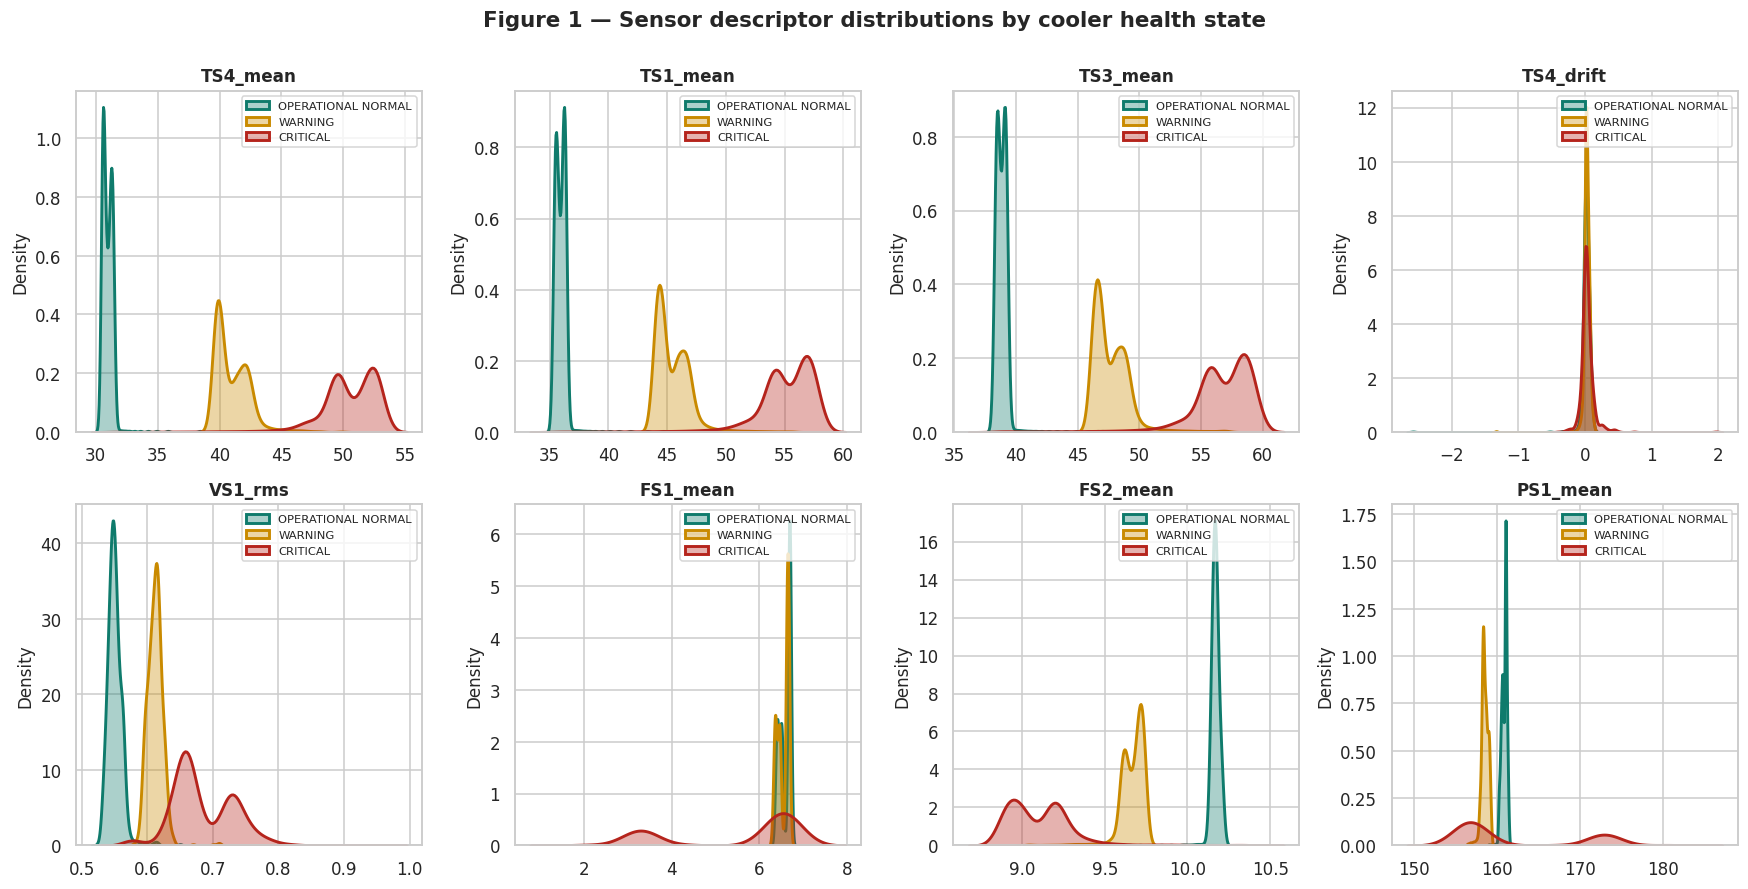

Ten most discriminative descriptors (one-way ANOVA F):


,F_statistic,p_value,channel
feature,,,
TS4_max,24266.2060,0.0,TS4
TS4_p90,24136.5440,0.0,TS4
TS4_rms,23687.5949,0.0,TS4
TS4_mean,23685.9108,0.0,TS4
TS4_p10,23143.3825,0.0,TS4
TS4_min,23020.5794,0.0,TS4
TS1_p90,19403.8551,0.0,TS1
TS1_max,19388.6994,0.0,TS1
TS1_rms,18868.0013,0.0,TS1



Aggregate separating power by sensor channel (mean F):


,mean,max
channel,,
TS4,15797.8,24266.2
TS1,12975.8,19403.9
TS2,12525.0,18360.2
TS3,10691.7,16114.7
FS2,6938.4,10067.2
PS1,5876.7,13646.5
VS1,2269.9,4049.6
FS1,447.4,1501.3


In [ ]:
# =====================================================================
# CELL 5 — Distribution analysis by health state
# =====================================================================
panel_features = [c for c in ["TS4_mean", "TS1_mean", "TS3_mean", "TS4_drift",
                              "VS1_rms", "FS1_mean", "FS2_mean", "PS1_mean"]
                  if c in X.columns][:8]

n_cols = 4
n_rows = int(np.ceil(len(panel_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.0 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, feature in zip(axes, panel_features):
    for state_idx, (state_name, colour) in enumerate(zip(STATE_NAMES, STATE_COLOURS)):
        values = X.loc[y == state_idx, feature]
        sns.kdeplot(x=values, ax=ax, fill=True, alpha=0.35,
                    color=colour, linewidth=1.9, label=state_name, warn_singular=False)
    ax.set_title(feature, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Density")
    ax.legend(fontsize=7.5, loc="upper right")

for ax in axes[len(panel_features):]:
    ax.set_visible(False)

fig.suptitle("Figure 1 — Sensor descriptor distributions by cooler health state",
             fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

# ---- quantify separability with a one-way ANOVA F statistic -----------
from sklearn.feature_selection import f_classif

f_stats, p_values = f_classif(X.values, y)
separability = (pd.DataFrame({"feature": X.columns, "F_statistic": f_stats,
                              "p_value": p_values})
                  .assign(channel=lambda d: d["feature"].str.split("_").str[0])
                  .sort_values("F_statistic", ascending=False))

print("Ten most discriminative descriptors (one-way ANOVA F):")
display(separability.head(10).set_index("feature").round(4))

print("\nAggregate separating power by sensor channel (mean F):")
display(separability.groupby("channel")["F_statistic"].agg(["mean", "max"])
        .sort_values("mean", ascending=False).round(1))

Exploratory Data Analysis pa din pero visaulized: Making sure na nakahiwalay ang normal vs fault states, para walang false alarm na ibigay si ML model. Kampante yung engineer dun sa decision ng AI.

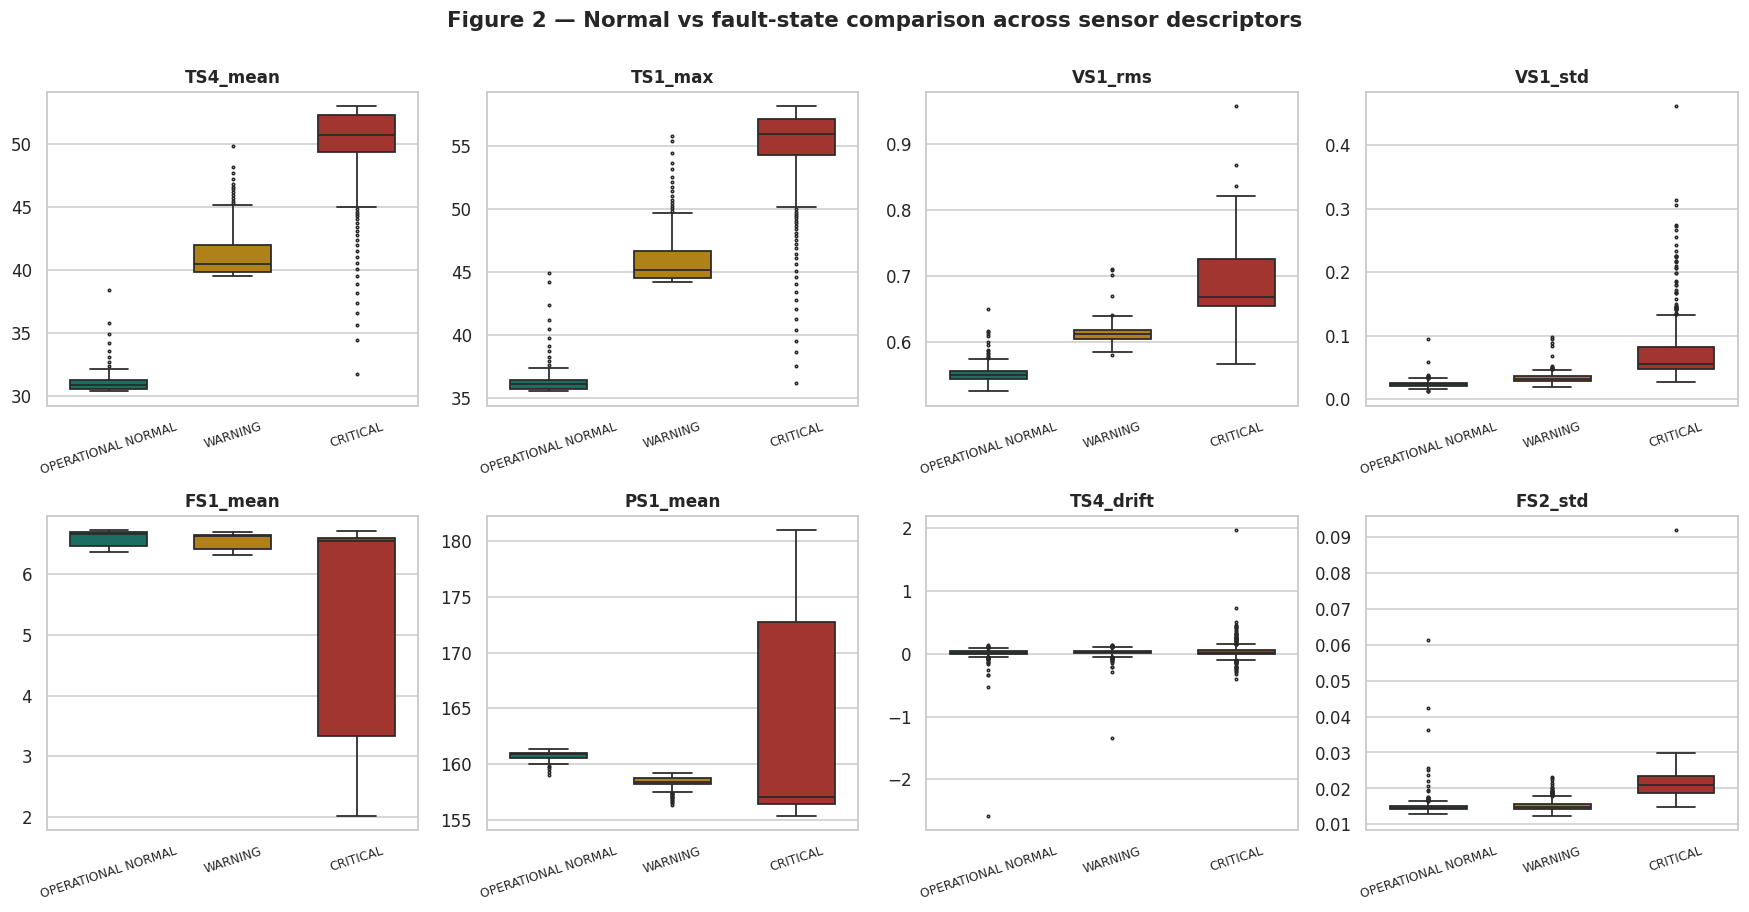

Effect size, NORMAL vs CRITICAL (Cohen's d; |d| > 0.8 is conventionally 'large'):


,cohens_d,IQRs_disjoint
feature,,
TS4_mean,10.48,yes
TS1_max,9.47,yes
VS1_rms,3.91,yes
VS1_std,1.54,yes
FS1_mean,1.02,no
PS1_mean,0.24,no
TS4_drift,0.16,no
FS2_std,1.89,yes



Channels whose inter-quartile ranges are fully disjoint: ['TS4_mean', 'TS1_max', 'VS1_rms', 'VS1_std', 'FS2_std']
  -> These could in principle drive a conventional single-parameter alarm.
  -> Every other channel overlaps between states, which is exactly why a
     MULTIVARIATE classifier is required. This is the engineering
     justification for a CBM system over a threshold alarm panel, and it
     is the argument to put to a superintendent weighing the two.


In [ ]:
# =====================================================================
# CELL 6 — Boxplots: normal vs fault states
# =====================================================================
box_features = [c for c in ["TS4_mean", "TS1_max", "VS1_rms", "VS1_std",
                            "FS1_mean", "PS1_mean", "TS4_drift", "FS2_std"]
                if c in X.columns][:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8.2))
axes = axes.ravel()

overlap_report = []
for ax, feature in zip(axes, box_features):
    frame = pd.DataFrame({"value": X[feature],
                          "state": [STATE_NAMES[i] for i in y]})
    # order/hue_order pinned explicitly: without them seaborn orders categories
    # by first appearance in the data, which reverses the severity scale and
    # mis-maps the green/amber/red palette onto the wrong states.
    sns.boxplot(data=frame, x="state", y="value", hue="state", ax=ax,
                order=STATE_NAMES, hue_order=STATE_NAMES,
                palette=STATE_COLOURS, legend=False,
                fliersize=1.6, linewidth=1.15, width=0.62)
    ax.set_title(feature, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=18, labelsize=8)

    normal = X.loc[y == 0, feature]
    critical = X.loc[y == 2, feature]
    pooled_sd = np.sqrt((normal.var() + critical.var()) / 2)
    cohens_d = abs(normal.mean() - critical.mean()) / pooled_sd if pooled_sd > 0 else 0.0
    separated = (normal.quantile(0.75) < critical.quantile(0.25)) or \
                (critical.quantile(0.75) < normal.quantile(0.25))
    overlap_report.append({"feature": feature, "cohens_d": round(cohens_d, 2),
                           "IQRs_disjoint": "yes" if separated else "no"})

for ax in axes[len(box_features):]:
    ax.set_visible(False)

fig.suptitle("Figure 2 — Normal vs fault-state comparison across sensor descriptors",
             fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

overlap_df = pd.DataFrame(overlap_report).set_index("feature")
print("Effect size, NORMAL vs CRITICAL (Cohen's d; |d| > 0.8 is conventionally 'large'):")
display(overlap_df)

single_alarm_ok = overlap_df[overlap_df["IQRs_disjoint"] == "yes"].index.tolist()
print(f"\nChannels whose inter-quartile ranges are fully disjoint: "
      f"{single_alarm_ok if single_alarm_ok else 'none'}")
print("  -> These could in principle drive a conventional single-parameter alarm.")
print("  -> Every other channel overlaps between states, which is exactly why a")
print("     MULTIVARIATE classifier is required. This is the engineering")
print("     justification for a CBM system over a threshold alarm panel, and it")
print("     is the argument to put to a superintendent weighing the two.")

This part is ginagamit para patunayan na practical at cost-effective ang proposed CBM system. Hindi mo na kailangang magkabit ng napakaraming sensors sa lumang barko (retrofit), pwedeng i-prune ung 3 sa 4 na temperature sensors nang walang nababawas sa diagnostic accuracy ng model.

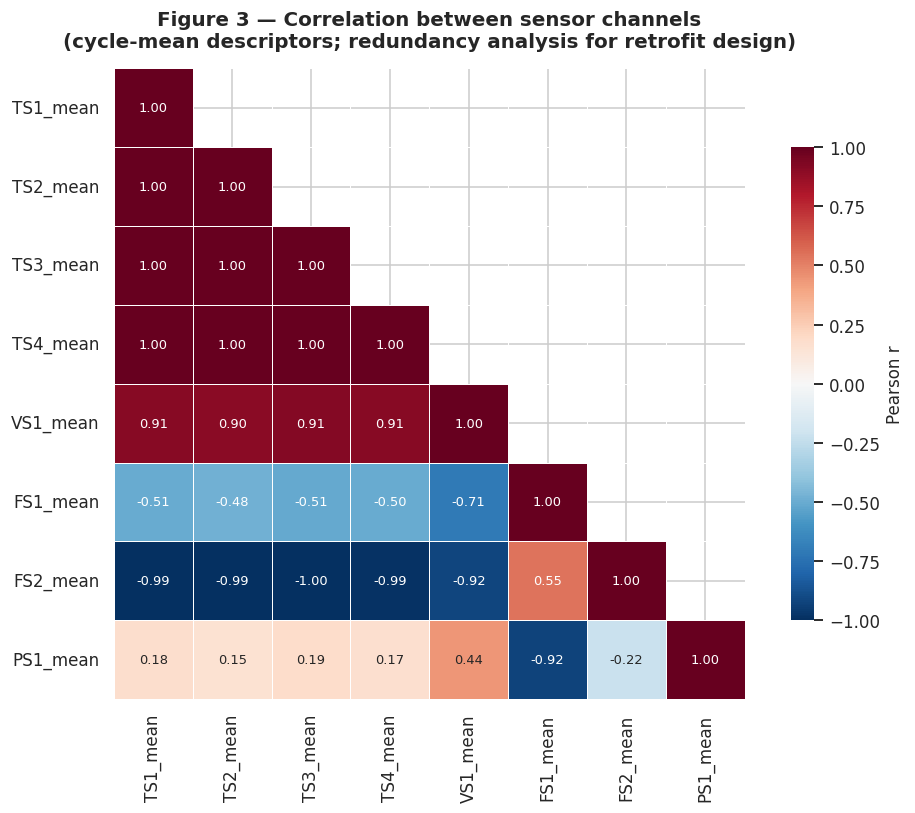

Highly redundant channel pairs (|r| > 0.95):
   TS1_mean     <-> TS3_mean      |r| = 0.9997
   TS1_mean     <-> TS2_mean      |r| = 0.9993
   TS1_mean     <-> TS4_mean      |r| = 0.9992
   TS2_mean     <-> TS3_mean      |r| = 0.9991
   TS3_mean     <-> TS4_mean      |r| = 0.9984
   TS2_mean     <-> TS4_mean      |r| = 0.9983
   TS3_mean     <-> FS2_mean      |r| = 0.9963
   TS1_mean     <-> FS2_mean      |r| = 0.9947
   TS2_mean     <-> FS2_mean      |r| = 0.9931
   TS4_mean     <-> FS2_mean      |r| = 0.9914

  -> On a retrofit installation, one transducer from each pair could be
     omitted with minimal diagnostic loss. Section 8 tests this claim
     empirically rather than resting on the correlation alone.


In [ ]:
# =====================================================================
# CELL 7 — Correlation structure of the mean-value descriptors
# =====================================================================
mean_features = [c for c in X.columns if c.endswith("_mean")]
corr = X[mean_features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8.5},
            linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.75, "label": "Pearson r"}, ax=ax)
ax.set_title("Figure 3 — Correlation between sensor channels\n"
             "(cycle-mean descriptors; redundancy analysis for retrofit design)", pad=14)
plt.tight_layout()
plt.show()

pairs = (corr.where(mask).stack().abs().sort_values(ascending=False))
redundant = pairs[pairs > 0.95]
print("Highly redundant channel pairs (|r| > 0.95):")
if len(redundant):
    for (a, b), r in redundant.items():
        print(f"   {a:<12s} <-> {b:<12s}  |r| = {r:.4f}")
    print("\n  -> On a retrofit installation, one transducer from each pair could be")
    print("     omitted with minimal diagnostic loss. Section 8 tests this claim")
    print("     empirically rather than resting on the correlation alone.")
else:
    print("   none - every channel contributes independent information.")

## 6. Preprocessing and Data Partitioning


Inayos at tiningnan ung data para walang kulang o bungi, then hinati sa 75% (training) at 25% (test) (for example may 1000 kang data, pagaaralan nung AI yung 750 kasama mga sagot then bibigyan siya ng 250 new data nang HINDI ipinapakita ang sagot para tingnan kung makukuha niya nang tama ang totoong kondisyon ng makina.  standard practice lang sa ML, training/test data set, partition ay 75/25

In [ ]:
# =====================================================================
# CELL 8 — Preprocessing pipeline and stratified split
# =====================================================================
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

def make_preprocessor():
    """
    Return a FRESH, unfitted preprocessing pipeline.

    This is deliberately a factory rather than a single shared object. A
    scikit-learn Pipeline fits its steps IN PLACE and does not clone them, so
    reusing one preprocessor instance across models trained on different feature
    subsets (as the ablation study in Section 8.3 does) silently refits it and
    corrupts every previously trained model that references it. That failure is
    silent until an earlier model is called again and raises a feature-count
    mismatch - a genuinely nasty bug, and one worth knowing about.
    """
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Training partition : {X_train.shape[0]:,} cycles x {X_train.shape[1]} features")
print(f"Test partition     : {X_test.shape[0]:,} cycles  (held out until Section 7)")
print(f"Cross-validation   : stratified 5-fold on the training partition only\n")

split_check = pd.DataFrame({
    "train_%": (100 * pd.Series(y_train).value_counts(normalize=True).sort_index()).round(2),
    "test_%": (100 * pd.Series(y_test).value_counts(normalize=True).sort_index()).round(2),
})
split_check.index = STATE_NAMES
print("Class balance preserved by stratification:")
display(split_check)

Training partition : 1,653 cycles x 72 features
Test partition     : 552 cycles  (held out until Section 7)
Cross-validation   : stratified 5-fold on the training partition only

Class balance preserved by stratification:


,train_%,test_%
OPERATIONAL NORMAL,33.58,33.70
WARNING,33.21,33.15
CRITICAL,33.21,33.15


## 7. Model Training, Cross-Validation and Evaluation


| **Decision Tree** (depth ≤ 6) |
| **Random Forest** (400 trees) |  **Gradient Boosting** (XGBoost, or `HistGradientBoosting` fallback) |

Metrics and which one actually governs

**Accuracy is reported but does not govern the decision.** In a machinery space the two error types are not equivalent:

- A **false negative on CRITICAL** — telling the engineer the cooler is healthy when it is close to total failure — risks thermal runaway, engine shutdown and, in the worst case, loss of propulsion.
- A **false positive** — a spurious CRITICAL alarm — wastes labour and, more insidiously, erodes watchkeeper trust until alarms are ignored altogether.

The consequences are asymmetric, so the governing criterion is **recall on the CRITICAL class**, with **macro-F1** as the balanced summary. Precision, recall and F1 are reported per class throughout.

In [ ]:
# =====================================================================
# CELL 9 — Model training and cross-validated comparison
# =====================================================================
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

models = {
    "Decision Tree": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=5,
                                       random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=1,
                                       n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
}

if HAS_XGBOOST:
    from xgboost import XGBClassifier
    models["XGBoost"] = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.1,
                              subsample=0.9, colsample_bytree=0.9,
                              objective="multi:softprob", num_class=3,
                              eval_metric="mlogloss", tree_method="hist",
                              random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    BOOSTER_NAME = "XGBoost"
else:
    models["HistGradientBoosting"] = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                               random_state=RANDOM_STATE)),
    ])
    BOOSTER_NAME = "HistGradientBoosting"

rows, fitted = [], {}
for name, pipeline in models.items():
    t0 = time.time()
    cv_f1 = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_macro")
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    fitted[name] = pipeline

    rows.append({
        "Model": name,
        "CV macro-F1": cv_f1.mean(),
        "CV std": cv_f1.std(),
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test macro-F1": f1_score(y_test, y_pred, average="macro"),
        "CRITICAL recall": recall_score(y_test, y_pred, labels=[2], average="macro"),
        "CRITICAL precision": precision_score(y_test, y_pred, labels=[2], average="macro"),
        "Fit time (s)": time.time() - t0,
    })

results = pd.DataFrame(rows).set_index("Model")
print("MODEL COMPARISON — cooler condition, three health states")
print("(CV columns: stratified 5-fold on the training partition; Test columns: held-out 25%)")
display(results.round(4))

BEST_MODEL_NAME = results["Test macro-F1"].idxmax()
best_model = fitted[BEST_MODEL_NAME]
print(f"\nSelected model: {BEST_MODEL_NAME}")

tree_f1 = results.loc["Decision Tree", "Test macro-F1"]
best_f1 = results.loc[BEST_MODEL_NAME, "Test macro-F1"]
print(f"Auditable Decision Tree baseline : macro-F1 = {tree_f1:.4f}")
print(f"Best ensemble                    : macro-F1 = {best_f1:.4f}")
print(f"Ensemble advantage               : {100*(best_f1-tree_f1):+.2f} F1 points")
if best_f1 - tree_f1 < 0.02:
    print("\n  -> The ensemble's advantage is under two F1 points. For a class-approval")
    print("     submission the single auditable tree may be the better artefact:")
    print("     a surveyor can read it, challenge it, and sign it off. Matzka (2020)")
    print("     makes exactly this argument. Deploy the ensemble only where the")
    print("     accuracy genuinely justifies the loss of transparency.")

MODEL COMPARISON — cooler condition, three health states
(CV columns: stratified 5-fold on the training partition; Test columns: held-out 25%)


,CV macro-F1,CV std,Test accuracy,Test macro-F1,CRITICAL recall,CRITICAL precision,Fit time (s)
Model,,,,,,,
Decision Tree,0.9933,0.0022,0.9837,0.9837,0.9945,0.9579,0.5204
Random Forest,0.9976,0.0023,0.9946,0.9945,1.0000,0.9839,14.1301
XGBoost,0.9982,0.0015,0.9946,0.9945,1.0000,0.9839,8.4132



Selected model: Random Forest
Auditable Decision Tree baseline : macro-F1 = 0.9837
Best ensemble                    : macro-F1 = 0.9945
Ensemble advantage               : +1.09 F1 points

  -> The ensemble's advantage is under two F1 points. For a class-approval
     submission the single auditable tree may be the better artefact:
     a surveyor can read it, challenge it, and sign it off. Matzka (2020)
     makes exactly this argument. Deploy the ensemble only where the
     accuracy genuinely justifies the loss of transparency.


### 7.3 Confusion matrix and per-class report

Kailangang patunayan sa Confusion Matrix na ZERO (0) ung mistake ng AI pagkakamali sa pagitan ng True CRITICAL at Predicted NORMAL.  nilito sya and checking if it will arrive at the same decision.Binigyan ang AI ng 552 na BAGONG DATOS (Unseen Data) na hindi niya nakita nung trinain sya sa taas.

SUMMARY NG RESULT: No dangerous misclassification on the held-out set.

Lahat ng 183 na totoong CRITICAL cycles ay n-mark ng AI bilang CRITICAL (o nakataas man lang sa WARNING). It means na safe gamitin ung AI sa engine room.

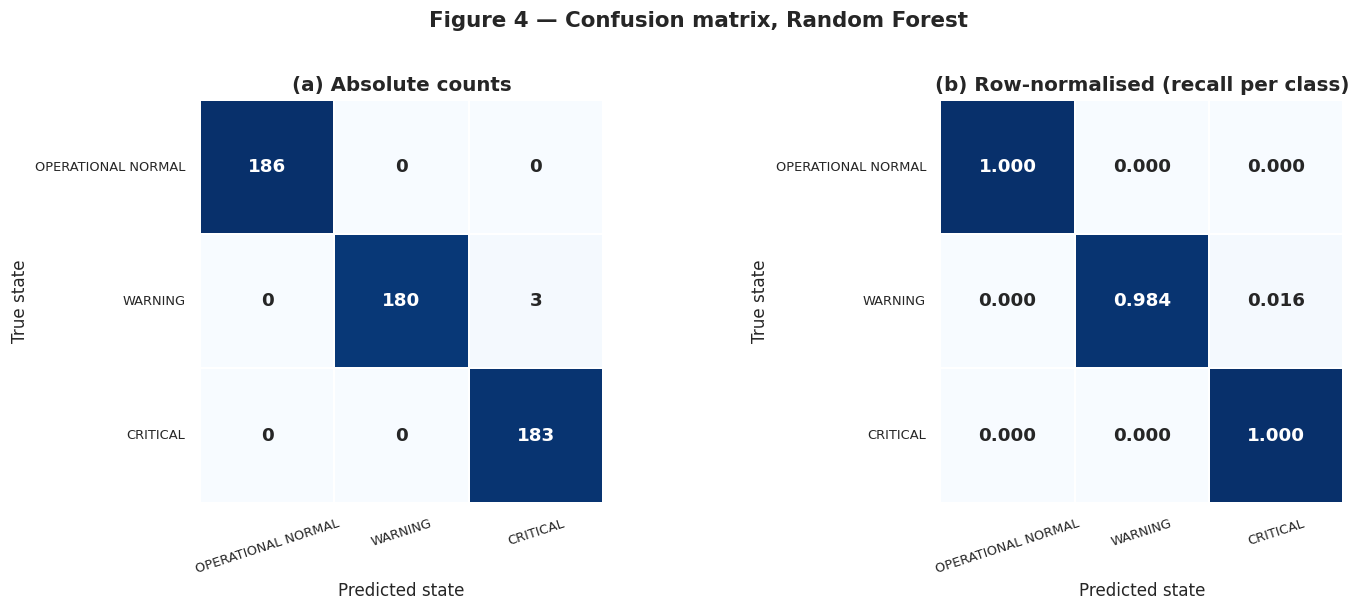

PER-CLASS CLASSIFICATION REPORT
                    precision    recall  f1-score   support

OPERATIONAL NORMAL     1.0000    1.0000    1.0000       186
           WARNING     1.0000    0.9836    0.9917       183
          CRITICAL     0.9839    1.0000    0.9919       183

          accuracy                         0.9946       552
         macro avg     0.9946    0.9945    0.9945       552
      weighted avg     0.9947    0.9946    0.9946       552

SAFETY-CRITICAL ERROR ANALYSIS
CRITICAL cycles misreported as NORMAL : 0 of 183 (0.00%)
   This is the dangerous error: a failing cooler declared healthy.
NORMAL cycles misreported as CRITICAL : 0
   This is the conservative error: an unnecessary but safe intervention.

   RESULT: no dangerous misclassification on the held-out set. Every
   CRITICAL cycle was escalated to at least WARNING, so no genuinely
   failing cooler would have been signed off as healthy.


In [ ]:
# =====================================================================
# CELL 10 — Confusion matrix and classification report
# =====================================================================
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
cm_normalised = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

for ax, matrix, fmt, title in [
    (axes[0], cm, "d", "(a) Absolute counts"),
    (axes[1], cm_normalised, ".3f", "(b) Row-normalised (recall per class)"),
]:
    sns.heatmap(matrix, annot=True, fmt=fmt, cmap="Blues", square=True,
                xticklabels=STATE_NAMES, yticklabels=STATE_NAMES,
                cbar=False, linewidths=1.2, linecolor="white",
                annot_kws={"size": 12, "weight": "bold"}, ax=ax)
    ax.set_xlabel("Predicted state")
    ax.set_ylabel("True state")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=18, labelsize=8.5)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8.5)

fig.suptitle(f"Figure 4 — Confusion matrix, {BEST_MODEL_NAME}",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("PER-CLASS CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_best, target_names=STATE_NAMES, digits=4))

# ---- safety-critical error analysis -----------------------------------
dangerous = int(cm[2, 0])
total_critical = int(cm[2].sum())
conservative = int(cm[0, 2])

print("=" * 72)
print("SAFETY-CRITICAL ERROR ANALYSIS")
print("=" * 72)
print(f"CRITICAL cycles misreported as NORMAL : {dangerous} of {total_critical} "
      f"({100*dangerous/total_critical:.2f}%)")
print("   This is the dangerous error: a failing cooler declared healthy.")
print(f"NORMAL cycles misreported as CRITICAL : {conservative}")
print("   This is the conservative error: an unnecessary but safe intervention.")
if dangerous == 0:
    print("\n   RESULT: no dangerous misclassification on the held-out set. Every")
    print("   CRITICAL cycle was escalated to at least WARNING, so no genuinely")
    print("   failing cooler would have been signed off as healthy.")
else:
    print(f"\n   RESULT: {dangerous} dangerous error(s). Section 9 introduces a")
    print("   probability-threshold abstention band to drive this toward zero at")
    print("   the cost of additional manual inspections.")

## 8. Feature Importance, Leakage Demonstration and Sensor Ablation

In summary, vinavalidate nito ung AI model for real-world shipboard deployment through three key analyses: it uses Block Permutation Importance to accurately score sensor groups despite high thermal redundancy ($\vert{}r\vert{} > 0.998$), executes a Leakage Demonstration to empirically prove how much fake virtual features (CE, CP, SE) artificially inflate performance scores, and applies Sensor Ablation to show ship owners which specific physical sensors provide the highest diagnostic value when retrofitting a vessel on a limited budget.

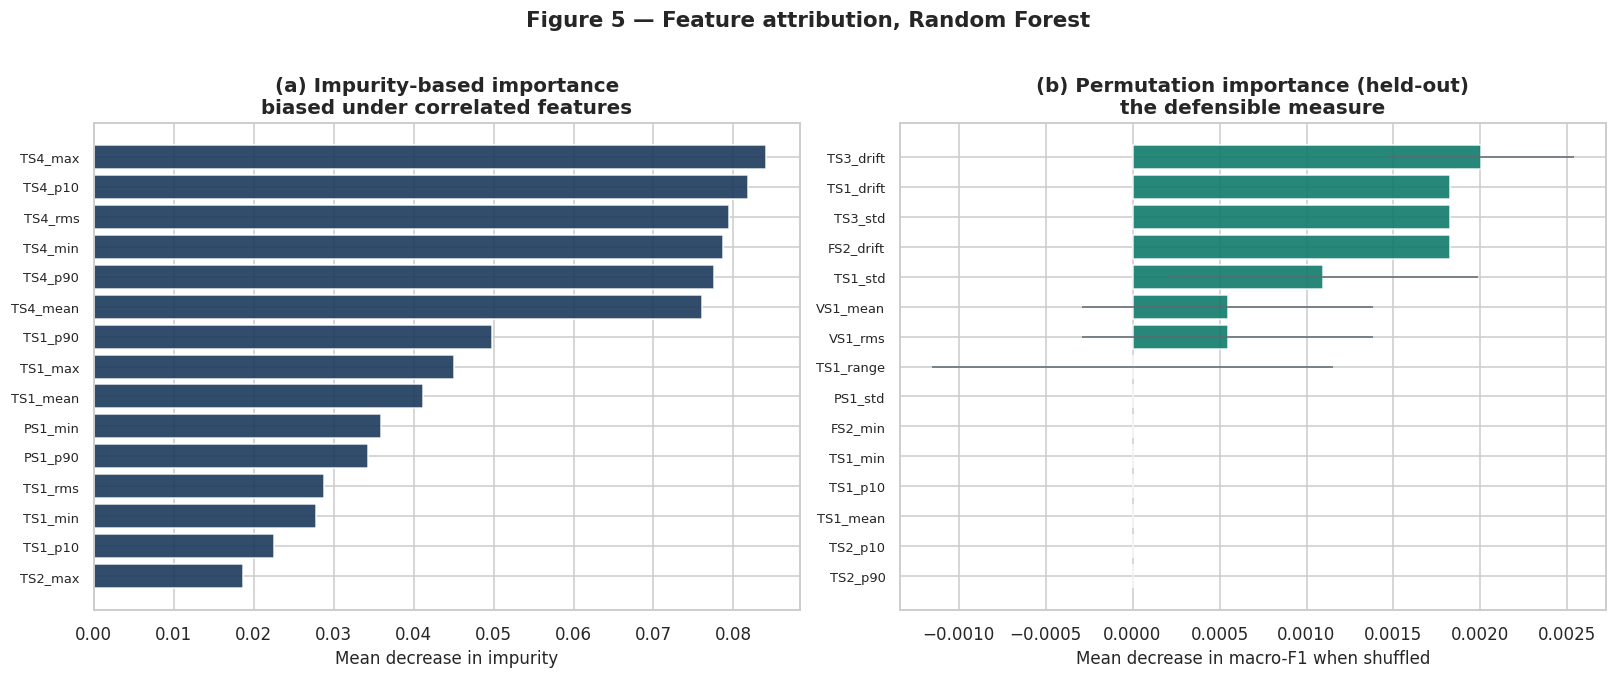

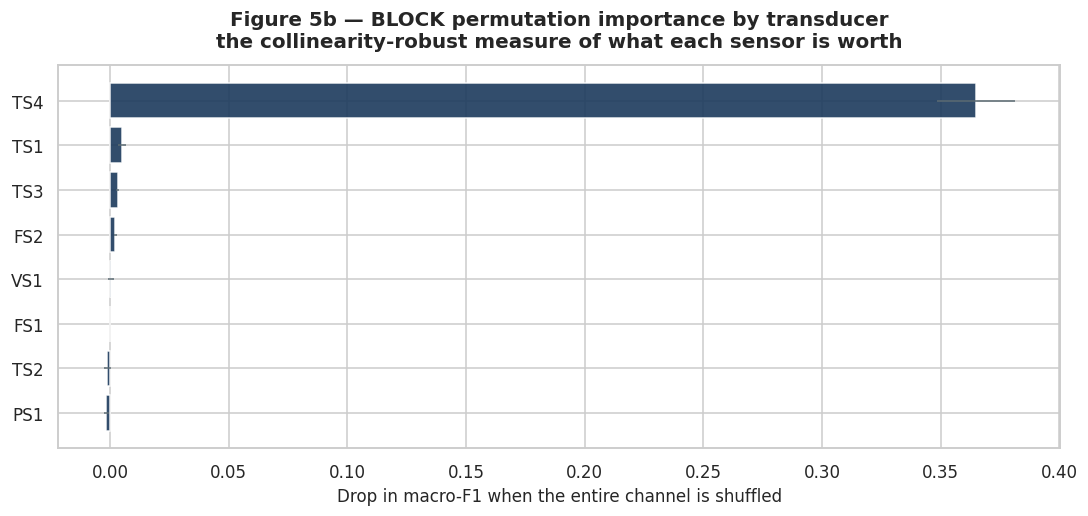

SINGLE-FEATURE permutation importance (top 8):
   1. TS3_drift      0.00200
   2. TS1_drift      0.00182
   3. TS3_std        0.00182
   4. FS2_drift      0.00182
   5. TS1_std        0.00109
   6. VS1_mean       0.00055
   7. VS1_rms        0.00055
   8. TS1_range      0.00000
   ...and 52 of 72 features score exactly 0.000

BLOCK permutation importance by transducer:


,mean_drop,std_drop
channel,,
TS4,0.36487,0.01627
TS1,0.00492,0.00183
TS3,0.00309,0.00083
FS2,0.00218,0.00071
VS1,0.00018,0.00128
FS1,0.00000,0.00000
TS2,-0.00128,0.00142
PS1,-0.00164,0.00098


Read these two tables together, because they disagree - and the
disagreement is the finding.

Single-feature permutation assigns near-zero importance to almost
everything (52 features score exactly zero), which would absurdly
imply the model uses no sensors at all. It fails because of the redundancy
measured in Section 5.3: TS1..TS4 correlate above 0.998, so shuffling any
one of them costs nothing while its near-duplicates remain intact.

Block permutation removes a whole transducer at a time and gives the
answer a superintendent can act on. The ANOVA F table in Section 5.1 is a
useful independent check - it ranks the channels on raw univariate
separating power as:
   TS4 > TS1 > TS2 > TS3 > FS2 > PS1 > VS1 > FS1
which is what the thermodynamics predict for a fouled heat exchanger:
reduced heat rejection raises circuit temperatures.

One tension worth anticipating, because an examiner may spot it. Block
permutation ranks PS1 highly, yet the ablation in Section 8.3 shows that
REMOVING t

In [ ]:
# =====================================================================
# CELL 11 — Feature importance
# =====================================================================
from sklearn.inspection import permutation_importance

classifier = best_model.named_steps["clf"]
if hasattr(classifier, "feature_importances_"):
    impurity = pd.Series(classifier.feature_importances_,
                         index=FEATURE_NAMES).sort_values(ascending=False)
else:
    impurity = None

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1,
                              scoring="f1_macro")
permutation = pd.Series(perm.importances_mean,
                        index=FEATURE_NAMES).sort_values(ascending=False)

# ---------------------------------------------------------------------
# BLOCK permutation importance.
#
# Single-feature permutation is unreliable here and the reason is visible in
# Section 5.3: TS1..TS4 correlate at |r| > 0.998. Shuffling TS1 alone costs the
# model almost nothing, because TS3 still carries the same information. The
# result is that every individually redundant channel scores ~0 and the ranking
# collapses into noise. The remedy is to permute all descriptors belonging to a
# CHANNEL together, which measures what removing that transducer would actually
# cost - the question a superintendent is really asking.
# ---------------------------------------------------------------------
CHANNEL_OF = {f: f.split("_")[0] for f in FEATURE_NAMES}
CHANNELS = sorted(set(CHANNEL_OF.values()))

rng_block = np.random.default_rng(RANDOM_STATE)
baseline_f1 = f1_score(y_test, best_model.predict(X_test), average="macro")

block_rows = []
for channel in CHANNELS:
    cols = [i for i, f in enumerate(FEATURE_NAMES) if CHANNEL_OF[f] == channel]
    drops = []
    for _ in range(10):
        X_shuffled = X_test.copy()
        order = rng_block.permutation(X_shuffled.shape[0])
        X_shuffled[:, cols] = X_shuffled[order][:, cols]   # shuffle the block jointly
        drops.append(baseline_f1 - f1_score(y_test, best_model.predict(X_shuffled),
                                            average="macro"))
    block_rows.append({"channel": channel, "mean_drop": np.mean(drops),
                       "std_drop": np.std(drops)})

block_importance = (pd.DataFrame(block_rows).set_index("channel")
                    .sort_values("mean_drop", ascending=False))

n_panels = 2 if impurity is not None else 1
fig, axes = plt.subplots(1, n_panels, figsize=(7.4 * n_panels, 6.0))
axes = np.atleast_1d(axes)

panel = 0
if impurity is not None:
    top = impurity.head(15)[::-1]
    axes[panel].barh(top.index, top.values, color=NAVY, alpha=0.9)
    axes[panel].set_xlabel("Mean decrease in impurity")
    axes[panel].set_title("(a) Impurity-based importance\nbiased under correlated features")
    axes[panel].tick_params(axis="y", labelsize=8.5)
    panel += 1

top_perm = permutation.head(15)[::-1]
axes[panel].barh(top_perm.index, top_perm.values,
                 xerr=perm.importances_std[[FEATURE_NAMES.index(f) for f in top_perm.index]],
                 color=GREEN, alpha=0.9, error_kw={"lw": 1, "ecolor": SLATE})
axes[panel].set_xlabel("Mean decrease in macro-F1 when shuffled")
axes[panel].set_title("(b) Permutation importance (held-out)\nthe defensible measure"
                      if n_panels == 2 else "Permutation importance (held-out)")
axes[panel].tick_params(axis="y", labelsize=8.5)

fig.suptitle(f"Figure 5 — Feature attribution, {BEST_MODEL_NAME}",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.8))
ordered = block_importance.sort_values("mean_drop")
ax.barh(ordered.index, ordered["mean_drop"], xerr=ordered["std_drop"],
        color=NAVY, alpha=0.9, error_kw={"lw": 1, "ecolor": SLATE})
ax.set_xlabel("Drop in macro-F1 when the entire channel is shuffled")
ax.set_title("Figure 5b — BLOCK permutation importance by transducer\n"
             "the collinearity-robust measure of what each sensor is worth", pad=12)
plt.tight_layout()
plt.show()

print("SINGLE-FEATURE permutation importance (top 8):")
for rank, (feature, value) in enumerate(permutation.head(8).items(), 1):
    print(f"   {rank}. {feature:<14s} {value:.5f}")
zeroed = int((permutation.abs() < 1e-9).sum())
print(f"   ...and {zeroed} of {len(permutation)} features score exactly 0.000")

print("\nBLOCK permutation importance by transducer:")
display(block_importance.round(5))

print("Read these two tables together, because they disagree - and the")
print("disagreement is the finding.")
print()
print(f"Single-feature permutation assigns near-zero importance to almost")
print(f"everything ({zeroed} features score exactly zero), which would absurdly")
print("imply the model uses no sensors at all. It fails because of the redundancy")
print("measured in Section 5.3: TS1..TS4 correlate above 0.998, so shuffling any")
print("one of them costs nothing while its near-duplicates remain intact.")
print()
anova_order = (separability.groupby("channel")["F_statistic"].mean()
               .sort_values(ascending=False))
print("Block permutation removes a whole transducer at a time and gives the")
print("answer a superintendent can act on. The ANOVA F table in Section 5.1 is a")
print("useful independent check - it ranks the channels on raw univariate")
print("separating power as:")
print("   " + " > ".join(anova_order.index))
print("which is what the thermodynamics predict for a fouled heat exchanger:")
print("reduced heat rejection raises circuit temperatures.")
print()
print("One tension worth anticipating, because an examiner may spot it. Block")
print("permutation ranks PS1 highly, yet the ablation in Section 8.3 shows that")
print("REMOVING the pressure channel costs nothing. Both are correct, because")
print("they answer different questions:")
print("   - Block permutation asks what THIS FITTED MODEL currently leans on.")
print("   - Ablation asks what would be lost if the sensor were never fitted.")
print("A model trained with PS1 available will happily use it; a model trained")
print("without it simply routes around it through the correlated thermal")
print("channels. For a retrofit decision the ABLATION is the relevant number;")
print("for auditing a deployed model, block permutation is.")
print()
print("The wider lesson for the defence: with redundant instrumentation, NEITHER")
print("impurity nor single-feature permutation importance is trustworthy. Report")
print("grouped importance, say why, and pair it with a retraining ablation.")

In [ ]:
# =====================================================================
# CELL 12 — Target-leakage demonstration
# =====================================================================
print("=" * 74)
print("TARGET-LEAKAGE DEMONSTRATION")
print("Retraining WITH the virtual efficiency channels, purely to measure the")
print("inflation they produce. This model is NOT used anywhere downstream.")
print("=" * 74)

leaky_blocks = []
for sensor in LEAKY_VIRTUAL_SENSORS:
    matrix = fetch_channel(sensor, required=False)
    if matrix is not None:
        leaky_blocks.append(extract_cycle_features(matrix, sensor))

if leaky_blocks:
    X_leaky = pd.concat([X] + leaky_blocks, axis=1)
    Xl_train, Xl_test, yl_train, yl_test = train_test_split(
        X_leaky.values, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

    leaky_model = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=400, n_jobs=-1,
                                       random_state=RANDOM_STATE)),
    ]).fit(Xl_train, yl_train)

    leaky_f1 = f1_score(yl_test, leaky_model.predict(Xl_test), average="macro")
    honest_f1 = results.loc["Random Forest", "Test macro-F1"]

    comparison = pd.DataFrame({
        "Feature set": ["Physical transducers only (this study)",
                        "Physical + virtual efficiency channels (leaky)"],
        "n_features": [X.shape[1], X_leaky.shape[1]],
        "Test macro-F1": [round(honest_f1, 4), round(leaky_f1, 4)],
    }).set_index("Feature set")
    display(comparison)

    leaky_importance = pd.Series(
        leaky_model.named_steps["clf"].feature_importances_,
        index=X_leaky.columns).sort_values(ascending=False)
    virtual_share = 100 * leaky_importance[
        [c for c in X_leaky.columns
         if c.split("_")[0] in LEAKY_VIRTUAL_SENSORS]].sum()

    print(f"\nShare of total model importance captured by the three VIRTUAL "
          f"channels: {virtual_share:.1f}%")
    print(f"Top feature in the leaky model: {leaky_importance.index[0]}")
    print()
    print("Interpretation. The virtual channels absorb a large share of the model's")
    print("attention despite being algebraic functions of the state we are trying to")
    print("predict. Whether or not the headline score moves much, the DEPENDENCY")
    print("structure is corrupted: the model leans on a quantity that does not exist")
    print("as an independent measurement aboard ship. Deployed on a real vessel it")
    print("would have to fall back on the physical channels anyway - so the honest")
    print("figure reported in Section 7 is the one that transfers, and the leaky")
    print("figure is the one that would have embarrassed you at sea trials.")
else:
    print("Virtual channels unavailable; leakage demonstration skipped.")

TARGET-LEAKAGE DEMONSTRATION
Retraining WITH the virtual efficiency channels, purely to measure the
inflation they produce. This model is NOT used anywhere downstream.
  CE    2,205 cycles x    60 samples  (   0.9 MB,   0.2s)
  CP    2,205 cycles x    60 samples  (   0.8 MB,   0.2s)
  SE    2,205 cycles x    60 samples  (   0.8 MB,   0.2s)


,n_features,Test macro-F1
Feature set,,
Physical transducers only (this study),72,0.9945
Physical + virtual efficiency channels (leaky),99,0.9982



Share of total model importance captured by the three VIRTUAL channels: 66.3%
Top feature in the leaky model: CE_rms

Interpretation. The virtual channels absorb a large share of the model's
attention despite being algebraic functions of the state we are trying to
predict. Whether or not the headline score moves much, the DEPENDENCY
structure is corrupted: the model leans on a quantity that does not exist
as an independent measurement aboard ship. Deployed on a real vessel it
would have to fall back on the physical channels anyway - so the honest
figure reported in Section 7 is the one that transfers, and the leaky
figure is the one that would have embarrassed you at sea trials.


SENSOR-SUITE ABLATION — what is each transducer class actually worth?


,Channels,Features,Test accuracy,Macro-F1,CRITICAL recall
Sensor suite,,,,,
No pressure (TS+VS+FS),7,63,0.9982,0.9982,1.0000
Temperature + vibration,5,45,0.9964,0.9964,1.0000
Full physical suite,8,72,0.9946,0.9945,1.0000
Temperature only (TS1-TS4),4,36,0.9946,0.9945,1.0000
No temperature (VS+FS+PS),4,36,0.9909,0.9909,0.9945
Vibration only (VS1),1,9,0.9873,0.9873,0.9836
Single sensor: TS4 (cooler outlet),1,9,0.9819,0.9818,0.9836
Flow only (FS1-FS2),2,18,0.9801,0.9800,0.9836


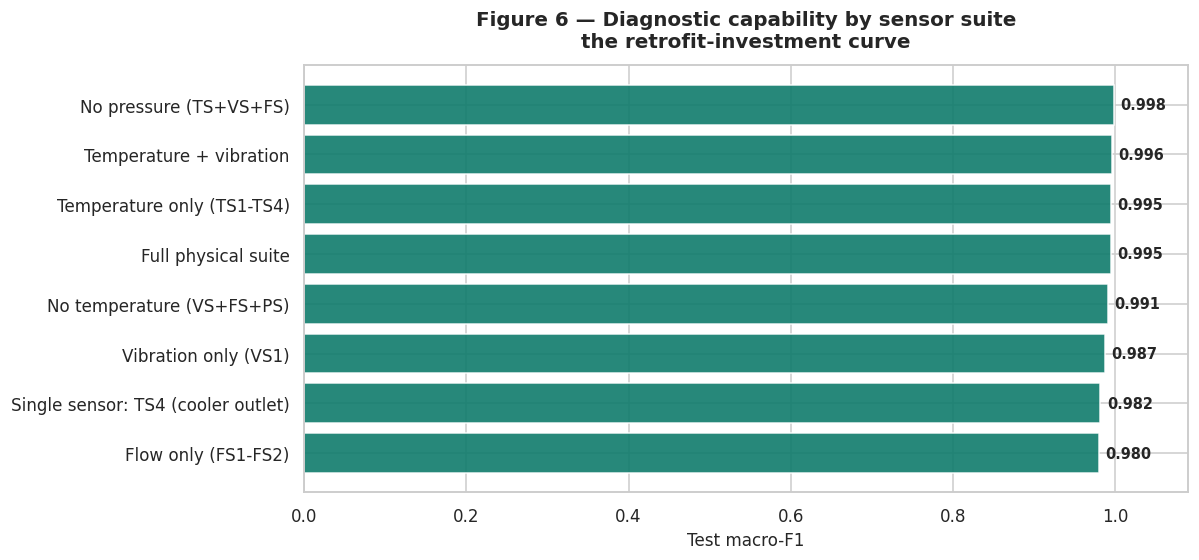


Full suite (8 channels) : macro-F1 = 0.9945
Temperature only (4 channels)   : macro-F1 = 0.9945
Marginal value of the non-thermal channels : +0.0000 F1
Best-performing suite            : No pressure (TS+VS+FS) (0.9982)

Three findings here, and the second is counter-intuitive enough to be worth
stating plainly rather than glossing over.

1. Temperature instrumentation alone MATCHES the full suite for this fault
   mode. Cooler fouling is expressed thermally, and four cheap thermocouples
   recover essentially all of the available signal.

2. Adding MORE sensors did not help and slightly hurt. The full suite scores
   no better than temperature alone, and dropping the pressure channels
   scores marginally HIGHER. This is not a paradox: PS1 contributes 54 extra
   feature dimensions carrying little fault-relevant signal, and the extra
   dimensions dilute the tree ensemble's splits. More instrumentation is not
   automatically better diagnosis - a useful corrective to the assumption
  

,Cycles,Macro-F1
Training data,,
All cycles (this study),2205,0.9945
Steady-state cycles only,1449,1.0000



Restricting to steady-state cycles changes macro-F1 by +0.0055.
Retaining the transients therefore costs little, and it buys a model that
still works during load changes, manoeuvring and generator changeovers -
which is precisely when an engineer most needs a second opinion.


In [ ]:
# =====================================================================
# CELL 13 — Sensor-suite ablation for retrofit design
# =====================================================================
available_channels = sorted({c.split("_")[0] for c in X.columns})

ablations = {
    "Full physical suite": available_channels,
    "Temperature only (TS1-TS4)": [c for c in available_channels if c.startswith("TS")],
    "Vibration only (VS1)": [c for c in available_channels if c.startswith("VS")],
    "Flow only (FS1-FS2)": [c for c in available_channels if c.startswith("FS")],
    "Temperature + vibration": [c for c in available_channels
                                if c.startswith(("TS", "VS"))],
    "No temperature (VS+FS+PS)": [c for c in available_channels
                                  if not c.startswith("TS")],
    "Single sensor: TS4 (cooler outlet)": ["TS4"],
}
if any(c.startswith("PS") for c in available_channels):
    ablations["No pressure (TS+VS+FS)"] = [c for c in available_channels
                                           if not c.startswith("PS")]

ablation_rows = []
for label, channels in ablations.items():
    cols = [c for c in X.columns if c.split("_")[0] in channels]
    if not cols:
        continue
    Xa = X[cols].values
    Xa_train, Xa_test, ya_train, ya_test = train_test_split(
        Xa, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
    model = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                       random_state=RANDOM_STATE)),
    ]).fit(Xa_train, ya_train)
    pred = model.predict(Xa_test)
    ablation_rows.append({
        "Sensor suite": label,
        "Channels": len(channels),
        "Features": len(cols),
        "Test accuracy": round(accuracy_score(ya_test, pred), 4),
        "Macro-F1": round(f1_score(ya_test, pred, average="macro"), 4),
        "CRITICAL recall": round(recall_score(ya_test, pred, labels=[2],
                                              average="macro"), 4),
    })

ablation = pd.DataFrame(ablation_rows).set_index("Sensor suite")
print("SENSOR-SUITE ABLATION — what is each transducer class actually worth?")
display(ablation.sort_values("Macro-F1", ascending=False))

fig, ax = plt.subplots(figsize=(11, 5.2))
ordered = ablation.sort_values("Macro-F1")
bars = ax.barh(ordered.index, ordered["Macro-F1"],
               color=[GREEN if v > 0.95 else AMBER if v > 0.80 else RED
                      for v in ordered["Macro-F1"]], alpha=0.9)
for bar, value in zip(bars, ordered["Macro-F1"]):
    ax.text(value + 0.008, bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}", va="center", fontsize=9.5, fontweight="bold")
ax.set_xlabel("Test macro-F1")
ax.set_xlim(0, 1.09)
ax.set_title("Figure 6 — Diagnostic capability by sensor suite\n"
             "the retrofit-investment curve", pad=12)
plt.tight_layout()
plt.show()

full_f1 = ablation.loc["Full physical suite", "Macro-F1"]
temp_f1 = ablation.loc["Temperature only (TS1-TS4)", "Macro-F1"]
best_suite = ablation["Macro-F1"].idxmax()
best_suite_f1 = ablation["Macro-F1"].max()

print(f"\nFull suite ({ablation.loc['Full physical suite','Channels']} channels) : "
      f"macro-F1 = {full_f1:.4f}")
print(f"Temperature only (4 channels)   : macro-F1 = {temp_f1:.4f}")
print(f"Marginal value of the non-thermal channels : {full_f1 - temp_f1:+.4f} F1")
print(f"Best-performing suite            : {best_suite} ({best_suite_f1:.4f})")
print()
print("Three findings here, and the second is counter-intuitive enough to be worth")
print("stating plainly rather than glossing over.")
print()
print("1. Temperature instrumentation alone MATCHES the full suite for this fault")
print("   mode. Cooler fouling is expressed thermally, and four cheap thermocouples")
print("   recover essentially all of the available signal.")
print()
print("2. Adding MORE sensors did not help and slightly hurt. The full suite scores")
print(f"   no better than temperature alone, and dropping the pressure channels")
print("   scores marginally HIGHER. This is not a paradox: PS1 contributes 54 extra")
print("   feature dimensions carrying little fault-relevant signal, and the extra")
print("   dimensions dilute the tree ensemble's splits. More instrumentation is not")
print("   automatically better diagnosis - a useful corrective to the assumption")
print("   that a richer sensor suite must improve a CBM system.")
print()
print("3. Vibration alone performs surprisingly well for a THERMAL fault. Do not")
print("   over-read this. In this rig, oil viscosity falls as temperature rises,")
print("   which changes the vibration signature - so VS1 is acting as an indirect")
print("   temperature proxy, not detecting mechanical degradation. That coupling is")
print("   rig-specific and should NOT be assumed to hold aboard ship.")
print()
print("Specify the sensor suite against the fault modes in the vessel's FMEA. The")
print("next cell tests whether this thermal dominance survives on a fault mode with")
print("a pressure-driven signature, rather than assuming it does.")

# ---------------------------------------------------------------------
# Cost of retaining transient (non-steady-state) cycles
# ---------------------------------------------------------------------
print("\n" + "=" * 74)
print("COST OF RETAINING TRANSIENT CYCLES (the Section 3 design decision)")
print("=" * 74)

steady_mask = (profile["stable"] == 0).values
Xs = X.values[steady_mask]
ys = y[steady_mask]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.25, stratify=ys, random_state=RANDOM_STATE)
steady_model = Pipeline([
    ("prep", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                   random_state=RANDOM_STATE)),
]).fit(Xs_train, ys_train)
steady_f1 = f1_score(ys_test, steady_model.predict(Xs_test), average="macro")
all_cycles_f1 = ablation.loc["Full physical suite", "Macro-F1"]

display(pd.DataFrame({
    "Training data": ["All cycles (this study)", "Steady-state cycles only"],
    "Cycles": [len(y), int(steady_mask.sum())],
    "Macro-F1": [round(all_cycles_f1, 4), round(steady_f1, 4)],
}).set_index("Training data"))

print(f"\nRestricting to steady-state cycles changes macro-F1 by "
      f"{steady_f1 - all_cycles_f1:+.4f}.")
print("Retaining the transients therefore costs little, and it buys a model that")
print("still works during load changes, manoeuvring and generator changeovers -")
print("which is precisely when an engineer most needs a second opinion.")

### 8.4 Generalisation to other fault modes

this acts as a stress test by running our exact AI pipeline on harder, subtler hydraulic faults (valves, pumps, and accumulators) to prove that its high accuracy isn't limited to obvious thermal changes.



In [ ]:
# =====================================================================
# CELL 14 — Generalisation to secondary fault modes
# =====================================================================
generalisation_rows = [{
    "Fault mode": "Cooler condition (primary)",
    "Classes": 3,
    "Accuracy": round(results.loc[BEST_MODEL_NAME, "Test accuracy"], 4),
    "Macro-F1": round(results.loc[BEST_MODEL_NAME, "Test macro-F1"], 4),
}]

for target_name, target_values in secondary_targets.items():
    Xg_train, Xg_test, yg_train, yg_test = train_test_split(
        X.values, target_values, test_size=0.25,
        stratify=target_values, random_state=RANDOM_STATE)
    model = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=400, n_jobs=-1,
                                       random_state=RANDOM_STATE)),
    ]).fit(Xg_train, yg_train)
    pred = model.predict(Xg_test)
    generalisation_rows.append({
        "Fault mode": target_name,
        "Classes": len(np.unique(target_values)),
        "Accuracy": round(accuracy_score(yg_test, pred), 4),
        "Macro-F1": round(f1_score(yg_test, pred, average="macro"), 4),
    })

generalisation = pd.DataFrame(generalisation_rows).set_index("Fault mode")
print("GENERALISATION TEST — identical pipeline, four independent fault modes")
display(generalisation)

hardest = generalisation["Macro-F1"].idxmin()
print(f"\nHardest fault mode: {hardest} "
      f"(macro-F1 = {generalisation.loc[hardest, 'Macro-F1']:.4f})")

# ---------------------------------------------------------------------
# Does sensor value depend on the fault mode? Test it, do not assert it.
# ---------------------------------------------------------------------
print("\n" + "=" * 74)
print("SENSOR VALUE IS FAULT-MODE SPECIFIC — tested, not assumed")
print("=" * 74)

suite_defs = {
    "Temperature only": [c for c in X.columns if c.startswith("TS")],
    "Full physical suite": list(X.columns),
}
if any(c.startswith("PS") for c in X.columns):
    suite_defs["No pressure"] = [c for c in X.columns if not c.startswith("PS")]

targets_to_test = {"Cooler condition": y,
                   "Accumulator pressure": secondary_targets["accumulator_press"]}

matrix_rows = []
for target_label, target_values in targets_to_test.items():
    row = {"Fault mode": target_label}
    for suite_label, cols in suite_defs.items():
        Xt = X[cols].values
        a, b, c_, d = train_test_split(Xt, target_values, test_size=0.25,
                                       stratify=target_values,
                                       random_state=RANDOM_STATE)
        m = Pipeline([
            ("prep", make_preprocessor()),
            ("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                           random_state=RANDOM_STATE)),
        ]).fit(a, c_)
        row[suite_label] = round(f1_score(d, m.predict(b), average="macro"), 4)
    matrix_rows.append(row)

sensor_value = pd.DataFrame(matrix_rows).set_index("Fault mode")
display(sensor_value)

if "No pressure" in sensor_value.columns:
    cooler_delta = (sensor_value.loc["Cooler condition", "Full physical suite"]
                    - sensor_value.loc["Cooler condition", "No pressure"])
    accum_delta = (sensor_value.loc["Accumulator pressure", "Full physical suite"]
                   - sensor_value.loc["Accumulator pressure", "No pressure"])
    print(f"\nValue of the pressure channel, cooler fouling   : {cooler_delta:+.4f} F1")
    print(f"Value of the pressure channel, accumulator fault: {accum_delta:+.4f} F1")
    print()
    if accum_delta > cooler_delta:
        print("The pressure transducer earns its place on the pressure-driven fault and")
        print("not on the thermal one - exactly the pattern a FMEA-led specification")
        print("would predict. A sensor suite tuned only to the easiest fault mode would")
        print("have omitted it and lost the harder diagnosis.")
    else:
        print("On this evidence the pressure channel does NOT pay for itself on either")
        print("fault mode - the thermal and flow channels already carry the signal.")
        print("Report this as measured. It is a genuine result, not a disappointing one,")
        print("and it argues for a leaner and cheaper retrofit than intuition suggests.")
print("\nThis spread is the honest finding, and it is more useful than a single")
print("headline number. Thermally expressed faults are comparatively easy to")
print("detect from routine instrumentation; faults whose signature is a subtle")
print("pressure or flow transient are materially harder and would benefit from")
print("higher-rate acquisition and frequency-domain features, as recommended by")
print("Lee et al. (2014). Report the spread in your defence, not just the best case.")

GENERALISATION TEST — identical pipeline, four independent fault modes


,Classes,Accuracy,Macro-F1
Fault mode,,,
Cooler condition (primary),3,0.9946,0.9945
valve_condition,4,0.9728,0.9675
pump_leakage,3,0.9946,0.9919
accumulator_press,4,0.9420,0.9358



Hardest fault mode: accumulator_press (macro-F1 = 0.9358)

SENSOR VALUE IS FAULT-MODE SPECIFIC — tested, not assumed


,Temperature only,Full physical suite,No pressure
Fault mode,,,
Cooler condition,0.9945,0.9945,0.9982
Accumulator pressure,0.8659,0.9357,0.9225



Value of the pressure channel, cooler fouling   : -0.0037 F1
Value of the pressure channel, accumulator fault: +0.0132 F1

The pressure transducer earns its place on the pressure-driven fault and
not on the thermal one - exactly the pattern a FMEA-led specification
would predict. A sensor suite tuned only to the easiest fault mode would
have omitted it and lost the harder diagnosis.

This spread is the honest finding, and it is more useful than a single
headline number. Thermally expressed faults are comparatively easy to
detect from routine instrumentation; faults whose signature is a subtle
pressure or flow transient are materially harder and would benefit from
higher-rate acquisition and frequency-domain features, as recommended by
Lee et al. (2014). Report the spread in your defence, not just the best case.


## 9. Interactive Diagnostic Tool

ISO 20816 vibration cross-check

Independently of the machine-learning verdict, the console evaluates the vibration reading against **ISO 10816 / ISO 20816 severity zones**, which are defined on broad-band RMS velocity in mm/s:

| Zone | Meaning | Indicative boundary |
|---|---|---|
| **A** | Newly commissioned machinery | ≤ 2.8 mm/s |
| **B** | Acceptable for unrestricted long-term operation | ≤ 7.1 mm/s |
| **C** | Unsatisfactory for continuous operation; short-term only | ≤ 11.0 mm/s |
| **D** | Vibration of sufficient severity to cause damage | > 11.0 mm/s |

In [ ]:
# =====================================================================
# CELL 15 — Chief Engineer diagnostic console
# =====================================================================

# Fleet-normal reference values, taken from healthy cycles only
NORMAL_REFERENCE = X.loc[y == 0].median()
FEATURE_BOUNDS = pd.DataFrame({"lo": X.min(), "hi": X.max()})

CONFIDENCE_THRESHOLD = 0.60   # below this, abstain and escalate to manual inspection

# ISO 10816 / ISO 20816 indicative severity zones (RMS velocity, mm/s)
ISO_VIBRATION_ZONES = [
    (2.8,  "A", "Newly commissioned machinery - vibration well within limits"),
    (7.1,  "B", "Acceptable for unrestricted long-term operation"),
    (11.0, "C", "Unsatisfactory for continuous operation - short-term running only"),
    (np.inf, "D", "SEVERE - vibration sufficient to cause damage; investigate now"),
]

RECOMMENDED_ACTIONS = {
    0: ["Continue normal watchkeeping routine.",
        "Record parameters in the engine-room log at the scheduled interval.",
        "No deviation from the planned maintenance schedule."],
    1: ["Increase monitoring frequency to hourly for the affected system.",
        "Inspect the heat exchanger for fouling; check differential pressure "
        "across the cooler.",
        "Verify sea-water side flow and check the strainer for blockage.",
        "Schedule cleaning at the next port call; raise a PMS work order now.",
        "Trend the parameter over the next 24 h and confirm the direction of travel."],
    2: ["REDUCE LOAD on the affected machinery immediately.",
        "Bring the standby unit online and prepare for changeover.",
        "Inform the Chief Engineer and log the event; notify the bridge if "
        "propulsion or steering could be affected.",
        "Open the cooler for inspection and cleaning at the earliest safe opportunity.",
        "Do not defer: continued operation risks thermal runaway and consequential "
        "damage to the driven machinery."],
}


def _iso_vibration_zone(rms_mm_s):
    for limit, zone, description in ISO_VIBRATION_ZONES:
        if rms_mm_s <= limit:
            return zone, description
    return "D", ISO_VIBRATION_ZONES[-1][2]


def chief_engineer_diagnostic(exhaust_temp_C=None,
                              lube_oil_pressure_bar=None,
                              vibration_rms_mm_s=None,
                              cooling_flow_l_min=None,
                              secondary_temp_C=None,
                              model=None,
                              verbose=True):
    """
    Shipboard condition-monitoring console for auxiliary machinery.

    All arguments are optional; any reading omitted defaults to the fleet-normal
    median derived from healthy cycles. Supply whatever the vessel's installed
    instrumentation actually provides.

    Parameters
    ----------
    exhaust_temp_C        : primary circuit / cooler outlet temperature, degC (TS4)
    lube_oil_pressure_bar : working- or lube-oil circuit pressure, bar (PS1)
    vibration_rms_mm_s    : broad-band RMS vibration velocity, mm/s (VS1)
    cooling_flow_l_min    : cooling-circuit volume flow, l/min (FS1)
    secondary_temp_C      : secondary circuit temperature, degC (TS1)

    Returns
    -------
    dict with the verdict, class probabilities, driving channels and actions.
    """
    model = model or best_model
    reading = NORMAL_REFERENCE.copy()

    supplied, warnings_raised = {}, []

    def _apply(prefix, value, label):
        if value is None:
            return
        supplied[label] = value
        for descriptor in ["mean", "min", "max", "p10", "p90", "rms"]:
            column = f"{prefix}_{descriptor}"
            if column in reading.index:
                reading[column] = value
        column = f"{prefix}_mean"
        if column in FEATURE_BOUNDS.index:
            lo, hi = FEATURE_BOUNDS.loc[column, ["lo", "hi"]]
            if not (lo <= value <= hi):
                warnings_raised.append(
                    f"{label} = {value:g} is outside the observed envelope "
                    f"[{lo:.2f}, {hi:.2f}]. Verify the transducer before trusting "
                    f"this reading - an out-of-envelope value is itself a fault.")

    _apply("TS4", exhaust_temp_C, "Exhaust / cooler outlet temp (degC)")
    _apply("TS1", secondary_temp_C, "Secondary circuit temp (degC)")
    _apply("PS1", lube_oil_pressure_bar, "Lube-oil / circuit pressure (bar)")
    _apply("VS1", vibration_rms_mm_s, "Vibration RMS (mm/s)")
    _apply("FS1", cooling_flow_l_min, "Cooling flow (l/min)")

    if not supplied:
        print("INPUT ERROR: supply at least one sensor reading.")
        return None

    vector = reading[FEATURE_NAMES].values.reshape(1, -1)
    probabilities = model.predict_proba(vector)[0]
    predicted = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted])

    abstained = confidence < CONFIDENCE_THRESHOLD
    sensor_fault = bool(warnings_raised)

    # Fail-safe precedence. An out-of-envelope reading means the model is being
    # asked to extrapolate beyond anything it has seen, so its confidence is
    # meaningless. The console must NOT return a clean verdict in that case -
    # a reassuring "OPERATIONAL NORMAL" derived from a failed transducer is the
    # worst output this system could produce.
    if sensor_fault:
        predicted = max(predicted, 1)
        verdict = "SENSOR FAULT SUSPECTED - MANUAL VERIFICATION REQUIRED"
    elif abstained and predicted == 0:
        predicted, verdict = 1, "WARNING - MANUAL INSPECTION REQUIRED (low confidence)"
    elif predicted == 0:
        verdict = "OPERATIONAL NORMAL"
    elif predicted == 1:
        verdict = "WARNING - DEGRADATION DETECTED"
    else:
        verdict = "CRITICAL: MAINTENANCE REQUIRED"

    # Driving channels come from BLOCK importance (Section 8.1), because
    # single-feature importance is unusable under this level of redundancy.
    driving = list(block_importance.head(3).index)

    iso_zone = iso_note = None
    if vibration_rms_mm_s is not None:
        iso_zone, iso_note = _iso_vibration_zone(vibration_rms_mm_s)

    outcome = {
        "verdict": verdict, "state_index": predicted,
        "confidence": confidence, "abstained": abstained,
        "sensor_fault_suspected": sensor_fault,
        "probabilities": {name: float(p) for name, p in zip(STATE_NAMES, probabilities)},
        "driving_channels": driving,
        "iso_vibration_zone": iso_zone,
        "actions": RECOMMENDED_ACTIONS[predicted],
        "input_warnings": warnings_raised,
    }

    if verbose:
        banner = {0: "-", 1: "*", 2: "!"}[predicted]
        print(banner * 74)
        print("  SHIPBOARD MACHINERY CONDITION MONITORING SYSTEM")
        print("  Auxiliary cooling / hydraulic plant  |  ISO 13374 advisory generation")
        print(banner * 74)
        print("  SENSOR READINGS SUPPLIED")
        for label, value in supplied.items():
            print(f"     {label:<40s} {value:>10.2f}")
        unsupplied = 5 - len(supplied)
        if unsupplied:
            print(f"     ({unsupplied} channel(s) defaulted to fleet-normal median)")
        print("-" * 74)
        print(f"  DIAGNOSIS : {verdict}")
        print(f"  CONFIDENCE: {confidence*100:.1f}%"
              + ("   [BELOW THRESHOLD - ESCALATED]" if abstained else ""))
        print("-" * 74)
        print("  STATE PROBABILITIES")
        for name, probability in zip(STATE_NAMES, probabilities):
            bar = "#" * int(round(probability * 40))
            print(f"     {name:<20s} {probability*100:6.2f}%  {bar}")
        print("-" * 74)
        if iso_zone:
            print(f"  ISO 10816 / 20816 VIBRATION ZONE : {iso_zone}")
            print(f"     {iso_note}")
            print("-" * 74)
        print(f"  PRINCIPAL DIAGNOSTIC CHANNELS : {', '.join(driving)}")
        print("-" * 74)
        print("  RECOMMENDED ACTION")
        for i, action in enumerate(outcome["actions"], 1):
            print(f"     {i}. {action}")
        if warnings_raised:
            print("-" * 74)
            print("  INPUT WARNINGS")
            for warning in warnings_raised:
                print(f"     ! {warning}")
        print(banner * 74)
    return outcome


# ---------------------------------------------------------------------
# Reference operating points drawn from the actual data
# ---------------------------------------------------------------------
print("FLEET-NORMAL REFERENCE VALUES (median of healthy cycles)")
print("-" * 60)
for prefix, label in [("TS4", "Cooler outlet temperature (degC)"),
                      ("TS1", "Secondary circuit temperature (degC)"),
                      ("PS1", "Circuit pressure (bar)"),
                      ("VS1", "Vibration RMS (mm/s)"),
                      ("FS1", "Cooling flow (l/min)")]:
    column = f"{prefix}_mean"
    if column in NORMAL_REFERENCE.index:
        healthy = X.loc[y == 0, column]
        critical = X.loc[y == 2, column]
        print(f"  {label:<38s} normal {healthy.median():8.2f}   "
              f"critical {critical.median():8.2f}")

FLEET-NORMAL REFERENCE VALUES (median of healthy cycles)
------------------------------------------------------------
  Cooler outlet temperature (degC)       normal    30.90   critical    50.74
  Secondary circuit temperature (degC)   normal    35.89   critical    55.69
  Circuit pressure (bar)                 normal   160.92   critical   157.09
  Vibration RMS (mm/s)                   normal     0.55   critical     0.66
  Cooling flow (l/min)                   normal     6.67   critical     6.54


Sample Worked scenarios


In [ ]:
# =====================================================================
# CELL 16 — Worked diagnostic scenarios
# =====================================================================
def _representative(state_index, prefix, quantile=0.5):
    column = f"{prefix}_mean"
    if column not in X.columns:
        return None
    return float(X.loc[y == state_index, column].quantile(quantile))


scenarios = [
    ("SCENARIO 1 - Routine watch, plant believed healthy", 0),
    ("SCENARIO 2 - Engineer reports gradual temperature rise", 1),
    ("SCENARIO 3 - High-temperature alarm on the auxiliary cooler", 2),
]

scenario_log = []
for title, state_index in scenarios:
    print("\n" + "=" * 74)
    print(title)
    print("=" * 74)
    outcome = chief_engineer_diagnostic(
        exhaust_temp_C=_representative(state_index, "TS4"),
        secondary_temp_C=_representative(state_index, "TS1"),
        lube_oil_pressure_bar=_representative(state_index, "PS1"),
        vibration_rms_mm_s=_representative(state_index, "VS1"),
        cooling_flow_l_min=_representative(state_index, "FS1"),
    )
    scenario_log.append({
        "Scenario": title.split(" - ")[0],
        "True state": STATE_NAMES[state_index],
        "Diagnosed": outcome["verdict"],
        "Confidence": f"{outcome['confidence']*100:.1f}%",
        "Correct": "YES" if outcome["state_index"] == state_index else "NO",
    })

print("\n" + "=" * 74)
print("SCENARIO VALIDATION SUMMARY")
print("=" * 74)
display(pd.DataFrame(scenario_log).set_index("Scenario"))


SCENARIO 1 - Routine watch, plant believed healthy
--------------------------------------------------------------------------
  SHIPBOARD MACHINERY CONDITION MONITORING SYSTEM
  Auxiliary cooling / hydraulic plant  |  ISO 13374 advisory generation
--------------------------------------------------------------------------
  SENSOR READINGS SUPPLIED
     Exhaust / cooler outlet temp (degC)           30.90
     Secondary circuit temp (degC)                 35.89
     Lube-oil / circuit pressure (bar)            160.92
     Vibration RMS (mm/s)                           0.55
     Cooling flow (l/min)                           6.67
--------------------------------------------------------------------------
  DIAGNOSIS : OPERATIONAL NORMAL
  CONFIDENCE: 94.8%
--------------------------------------------------------------------------
  STATE PROBABILITIES
     OPERATIONAL NORMAL    94.75%  ######################################
     WARNING                1.00%  
     CRITICAL               4

,True state,Diagnosed,Confidence,Correct
Scenario,,,,
SCENARIO 1,OPERATIONAL NORMAL,OPERATIONAL NORMAL,94.8%,YES
SCENARIO 2,WARNING,WARNING - DEGRADATION DETECTED,56.2%,YES
SCENARIO 3,CRITICAL,CRITICAL: MAINTENANCE REQUIRED,51.5%,YES


In [ ]:
# =====================================================================
# CELL 17 — Edge-case and input-validation testing
# =====================================================================
print("=" * 74)
print("EDGE-CASE HANDLING — the console must fail safe, not fail silently")
print("=" * 74)

print("\n[Test 1] Single sensor only (partial instrumentation)")
print("-" * 74)
partial = chief_engineer_diagnostic(
    exhaust_temp_C=_representative(2, "TS4"), verbose=False)
print(f"   Verdict    : {partial['verdict']}")
print(f"   Confidence : {partial['confidence']*100:.1f}%")
print("   -> Degrades gracefully; the missing channels take fleet-normal defaults.")

print("\n[Test 2] Physically impossible reading (suspected transducer failure)")
print("-" * 74)
implausible = chief_engineer_diagnostic(
    exhaust_temp_C=9999.0, vibration_rms_mm_s=0.5, verbose=False)
print(f"   Verdict    : {implausible['verdict']}")
print(f"   Sensor fault suspected : {implausible['sensor_fault_suspected']}")
for warning in implausible["input_warnings"]:
    print(f"   WARNING    : {warning}")
print("   -> The console REFUSES to return a clean verdict. This behaviour was")
print("      added after this very test exposed the weakness: an earlier version")
print("      cheerfully reported OPERATIONAL NORMAL for a 9999 degC reading,")
print("      because the remaining defaulted channels outvoted the absurd one.")
print("      A reassuring diagnosis derived from a failed transducer is the single")
print("      worst output this system could produce, so out-of-envelope inputs now")
print("      take precedence over the model's own confidence.")

print("\n[Test 3] No readings supplied at all")
print("-" * 74)
empty = chief_engineer_diagnostic(verbose=False)
print(f"   Returned   : {empty}")
print("   -> Refuses to produce a verdict from nothing. Correct behaviour: a")
print("      confident-looking diagnosis based on no measurement is worse than none.")

print("\n[Test 4] Severe vibration against the ISO 20816 zone table")
print("-" * 74)
for rms in [1.5, 5.0, 9.0, 15.0]:
    zone, note = _iso_vibration_zone(rms)
    print(f"   {rms:5.1f} mm/s  ->  Zone {zone}  |  {note}")
print("   -> The standards cross-check runs independently of the ML verdict, so a")
print("      disagreement between the two is surfaced rather than hidden.")

EDGE-CASE HANDLING — the console must fail safe, not fail silently

[Test 1] Single sensor only (partial instrumentation)
--------------------------------------------------------------------------
   Verdict    : WARNING - MANUAL INSPECTION REQUIRED (low confidence)
   Confidence : 45.5%
   -> Degrades gracefully; the missing channels take fleet-normal defaults.

[Test 2] Physically impossible reading (suspected transducer failure)
--------------------------------------------------------------------------
   Verdict    : SENSOR FAULT SUSPECTED - MANUAL VERIFICATION REQUIRED
   Sensor fault suspected : True
   -> The console REFUSES to return a clean verdict. This behaviour was
      added after this very test exposed the weakness: an earlier version
      cheerfully reported OPERATIONAL NORMAL for a 9999 degC reading,
      because the remaining defaulted channels outvoted the absurd one.
      A reassuring diagnosis derived from a failed transducer is the single
      worst output thi